# A Transformer-Based Approach for Raw EEG Classification

### 1. Setup and Imports

Import necessary libraries and set up the environment.



In [2]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

In [3]:
import numpy as np
from pathlib import Path
import re
import sys

src_path = Path('../src/eeg-bci-transformer-pipeline').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))
from datapreprocessing import EEGpreprocessing, EEGDataset
from train import EarlyStopper, EEGTrainer
from models import ScaledDotProductAttention, MultiHeadAttention, FeedForward, TransformerLayer, ConvolutionModule, EEGConformer, EEGTransformerConv1D

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Configuration and Hyperparameters

Define all model and training parameters

### 3. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [4]:
CURRENT_DIR = Path.cwd()

DATASET_PATH = (CURRENT_DIR.parent / "data" / "MotorMovement(03,07,011)") if CURRENT_DIR.name == "notebook" else (CURRENT_DIR / "data" / "MotorMovement(03,07,011)")

print(f"Percorso dataset utilizzato: {DATASET_PATH}")

edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

# Split riproducibile sui SOGGETTI (Test set isolato)
np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")

Percorso dataset utilizzato: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorMovement(03,07,011)
File EDF for Train/Validation: 294
File EDF for TEST: 33


Apply preprocessing  #momontaneamente lo faccio solo sul train/val perchè non sono sicura vada fatto sul test, riparlarne con luca

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import mne

X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  # 📊 Lista per salvare i valori numerici della PSD

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    # 1. CALCOLO CORRETTO DELLA PSD (Metodo moderno di MNE)
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch')
    
    # 2. ESTRAZIONE DEI VALORI NUMERICI DELLA PSD
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    # Shape di psd_values: (n_epochs, n_channels, n_freqs)
    
    # Salviamo i valori numerici associati al soggetto
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,                # Vettore delle frequenze (es. 1 Hz, 2 Hz, ...)
        'psd_data': psd_values,              # Valori di potenza spettrale
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2)) # Potenza media per canale
    })


    if len(epochs_mne) == 0:
        continue
    
    # Estraiamo i dati grezzi delle epoche
    X_raw = epochs_mne.get_data(copy=True) 

    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    labels = np.zeros(len(y), dtype=np.int64)
    labels[y == event_id['Left']] = 0
    labels[y == event_id['Right']] = 1

    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 project

/tmp/ipykernel_200979/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)
/tmp/ipykernel_200979/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)


/tmp/ipykernel_200979/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 project

In [19]:
'''
for i, record in enumerate(psd_records[:4]):
    print(f"--- Paziente {i+1} ---")
    print(f"Subject ID: {record['subject_id']}")
    print(f"Shape della PSD (epoche, canali, frequenze): {record['psd_data'].shape}")
    print(f"Potenza media per canale (primi 5 canali): {record['mean_power_per_channel'][:63]}")
    print("-" * 30)
'''

'\nfor i, record in enumerate(psd_records[:4]):\n    print(f"--- Paziente {i+1} ---")\n    print(f"Subject ID: {record[\'subject_id\']}")\n    print(f"Shape della PSD (epoche, canali, frequenze): {record[\'psd_data\'].shape}")\n    print(f"Potenza media per canale (primi 5 canali): {record[\'mean_power_per_channel\'][:63]}")\n    print("-" * 30)\n'

Convert to PyTorch tensors

In [6]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Dimensioni X_train_val grezzo: {X_training_validation_raw.shape}")
print(f"Dimensioni y_train_val: {y_training_validation.shape}")
print("Distribuzione etichette:", np.unique(y_training_validation, return_counts=True))

Dimensioni X_train_val grezzo: (4402, 64, 641)
Dimensioni y_train_val: (4402,)
Distribuzione etichette: (array([0, 1]), array([2203, 2199]))


In [7]:
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)


### Cross-Individual 3-Fold Cross-Validation and Random grid search to tuning hyperparameters

# GroupKFold

In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# 2. Parametri di Configurazione
BATCH_SIZE = 64
EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 1e-3
ALPHA_NOISE = 0.01

gkf = GroupKFold(n_splits=5)

# ==========================================
# 3. CICLO DI TRAINING CON FOLD E TRAINER PERSONALIZZATO
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 (Batch Size = {BATCH_SIZE}) ---")

    # A. Divisione dei dati grezzi in base al fold del GroupKFold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=0.4, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore (AdamW), Loss (con Label Smoothing) e Scheduler (Cosine Annealing)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    # H. Inizializzazione della tua classe EEGTrainer (che gestisce Early Stopper e Scheduler)
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    # I. Avvio dell'addestramento tramite il metodo della classe
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc:.4f} | Max Val Acc: {max(val_accuracies)*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
    # ==========================================
    plt.figure(figsize=(14, 5))

    # Pannello 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Fold {fold + 1}\n(AdamW + Scheduler + Early Stopping)')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Pannello 2: Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

  

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 (Batch Size = 64) ---


Epoch 01/30: train_loss=0.69449, val_loss=0.69312, val_acc=50.06%
Epoch 02/30: train_loss=0.69326, val_loss=0.69308, val_acc=50.29%
Epoch 03/30: train_loss=0.69222, val_loss=0.69268, val_acc=50.87%
Epoch 04/30: train_loss=0.68899, val_loss=0.69106, val_acc=52.26%
Epoch 05/30: train_loss=0.68141, val_loss=0.67868, val_acc=54.82%
Epoch 06/30: train_loss=0.66865, val_loss=0.66852, val_acc=58.07%
Epoch 07/30: train_loss=0.65259, val_loss=0.70546, val_acc=57.26%
Epoch 08/30: train_loss=0.63721, val_loss=0.77412, val_acc=52.96%
Epoch 09/30: train_loss=0.61774, val_loss=0.71155, val_acc=60.98%
Epoch 10/30: train_loss=0.58587, val_loss=0.66526, val_acc=62.72%
Epoch 11/30: train_loss=0.57240, val_loss=0.64973, val_acc=64.00%
Epoch 12/30: train_loss=0.54611, val_loss=0.63542, val_acc=69.22%
Epoch 13/30: train_loss=0.53296, val_loss=0.65459, val_acc=68.41%
Epoch 14/30: train_loss=0.51910, val_loss=0.68312, val_acc=66.67%
Epoch 15/30: train_loss=0.49156, val_loss=0.64944, val_acc=70.85%
Epoch 16/3

NameError: name 'best_val_loss' is not defined

# kfold

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 ---
Epoch 01/30: train_loss=0.69353, val_loss=0.69412, val_acc=49.83%
Epoch 02/30: train_loss=0.69308, val_loss=0.69497, val_acc=51.42%
Epoch 03/30: train_loss=0.69073, val_loss=0.69274, val_acc=53.92%
Epoch 04/30: train_loss=0.68823, val_loss=0.68860, val_acc=55.73%
Epoch 05/30: train_loss=0.67806, val_loss=0.68492, val_acc=56.98%
Epoch 06/30: train_loss=0.67067, val_loss=0.69561, val_acc=55.96%
Epoch 07/30: train_loss=0.67295, val_loss=0.66005, val_acc=59.48%
Epoch 08/30: train_loss=0.64720, val_loss=0.65668, val_acc=61.07%
Epoch 09/30: train_loss=0.63701, val_loss=0.64276, val_acc=66.97%
Epoch 10/30: train_loss=0.61027, val_loss=0.75102, val_acc=58.23%
Epoch 11/30: train_loss=0.61812, val_loss=0.74058, val_acc=59.82%
Epoch 12/30: train_loss=0.59898, val_loss=0.65249, val_acc=65.95%
Epoch 13/30: train_loss=0.59252, val_loss=0.64248, val_acc=69.47%
Epoch 14/30: train_loss=0.62201, val_loss=0.70796,

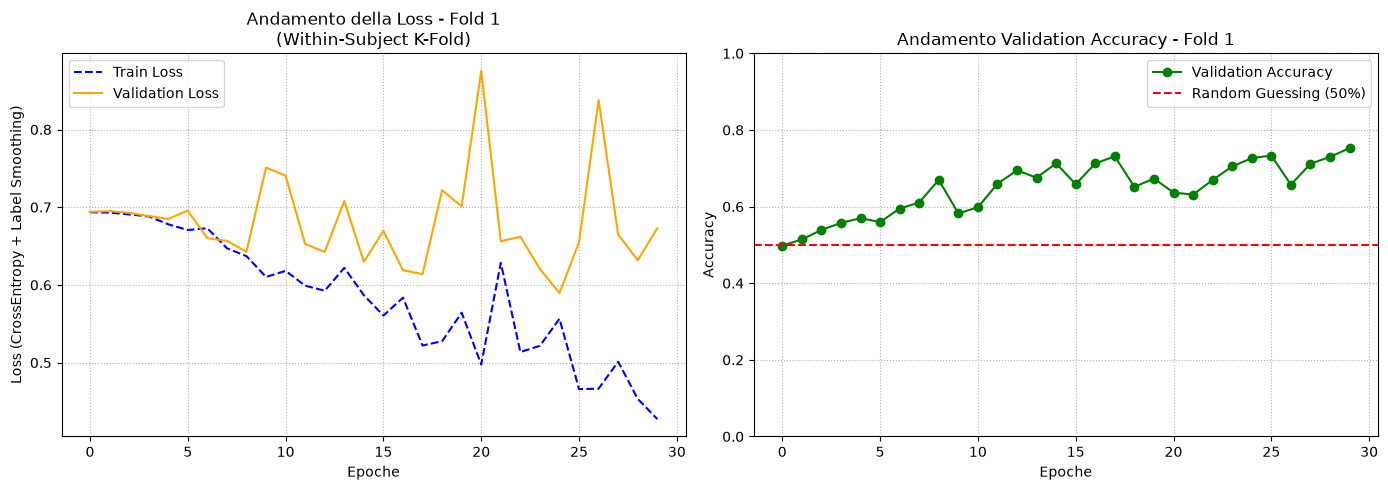


--- INIZIO TRAINING & VALIDAZIONE - FOLD 2/5 ---
Epoch 01/30: train_loss=0.69523, val_loss=0.69390, val_acc=48.81%
Epoch 02/30: train_loss=0.69355, val_loss=0.69216, val_acc=52.55%
Epoch 03/30: train_loss=0.69623, val_loss=0.69239, val_acc=49.04%
Epoch 04/30: train_loss=0.69175, val_loss=0.68992, val_acc=52.55%
Epoch 05/30: train_loss=0.68924, val_loss=0.68509, val_acc=55.16%
Epoch 06/30: train_loss=0.68470, val_loss=0.67679, val_acc=56.41%
Epoch 07/30: train_loss=0.68033, val_loss=0.68646, val_acc=54.37%
Epoch 08/30: train_loss=0.67559, val_loss=0.65281, val_acc=61.75%
Epoch 09/30: train_loss=0.65773, val_loss=0.64154, val_acc=61.98%
Epoch 10/30: train_loss=0.65122, val_loss=0.67189, val_acc=58.23%
Epoch 11/30: train_loss=0.62059, val_loss=0.61585, val_acc=66.97%
Epoch 12/30: train_loss=0.61277, val_loss=0.63805, val_acc=66.06%
Epoch 13/30: train_loss=0.59382, val_loss=0.69110, val_acc=61.75%
Epoch 14/30: train_loss=0.57475, val_loss=0.58280, val_acc=71.74%
Epoch 15/30: train_loss=0.

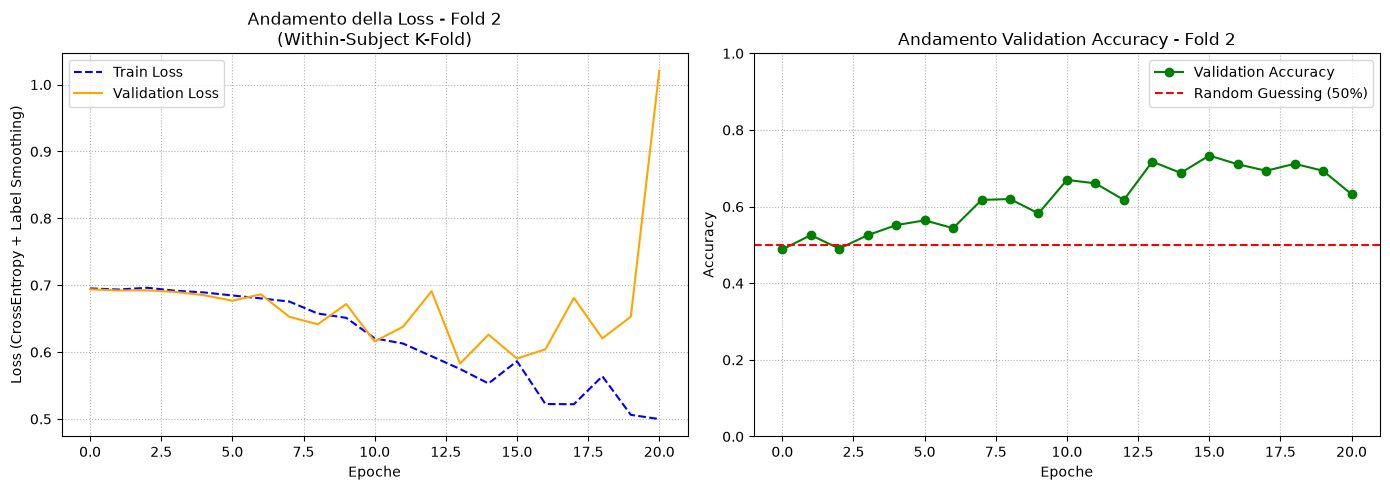


--- INIZIO TRAINING & VALIDAZIONE - FOLD 3/5 ---
Epoch 01/30: train_loss=0.69389, val_loss=0.69320, val_acc=50.11%
Epoch 02/30: train_loss=0.69337, val_loss=0.69304, val_acc=51.02%
Epoch 03/30: train_loss=0.69308, val_loss=0.69190, val_acc=51.36%
Epoch 04/30: train_loss=0.69232, val_loss=0.68767, val_acc=55.57%
Epoch 05/30: train_loss=0.68787, val_loss=0.67989, val_acc=55.00%
Epoch 06/30: train_loss=0.68338, val_loss=0.66947, val_acc=60.68%
Epoch 07/30: train_loss=0.66987, val_loss=0.66786, val_acc=61.02%
Epoch 08/30: train_loss=0.66843, val_loss=0.65580, val_acc=61.48%
Epoch 09/30: train_loss=0.65402, val_loss=0.66230, val_acc=56.82%
Epoch 10/30: train_loss=0.63062, val_loss=0.64600, val_acc=63.52%
Epoch 11/30: train_loss=0.62256, val_loss=0.64631, val_acc=65.11%
Epoch 12/30: train_loss=0.59654, val_loss=0.61375, val_acc=70.00%
Epoch 13/30: train_loss=0.59741, val_loss=0.60694, val_acc=68.75%
Epoch 14/30: train_loss=0.57798, val_loss=0.60769, val_acc=71.59%
Epoch 15/30: train_loss=0.

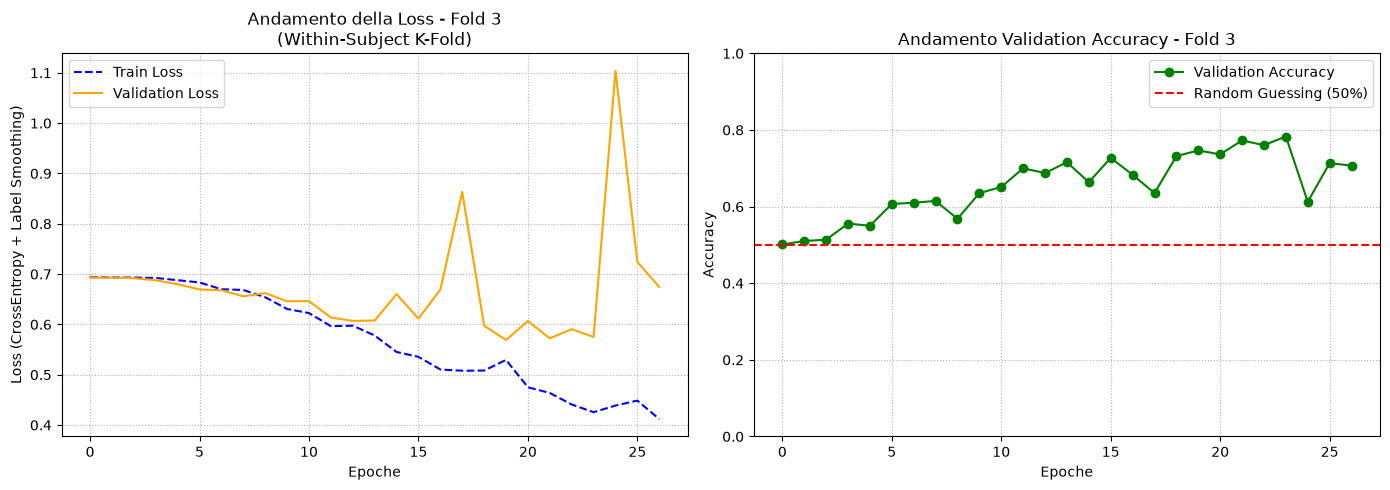


--- INIZIO TRAINING & VALIDAZIONE - FOLD 4/5 ---
Epoch 01/30: train_loss=0.69404, val_loss=0.69243, val_acc=51.82%
Epoch 02/30: train_loss=0.69375, val_loss=0.69219, val_acc=52.50%
Epoch 03/30: train_loss=0.69092, val_loss=0.68737, val_acc=53.64%
Epoch 04/30: train_loss=0.68642, val_loss=0.68668, val_acc=55.11%
Epoch 05/30: train_loss=0.67655, val_loss=0.70417, val_acc=52.95%
Epoch 06/30: train_loss=0.66328, val_loss=0.65145, val_acc=62.84%
Epoch 07/30: train_loss=0.64451, val_loss=0.63727, val_acc=66.36%
Epoch 08/30: train_loss=0.62274, val_loss=0.64910, val_acc=63.64%
Epoch 09/30: train_loss=0.61623, val_loss=0.62966, val_acc=64.66%
Epoch 10/30: train_loss=0.61789, val_loss=0.69090, val_acc=61.70%
Epoch 11/30: train_loss=0.59177, val_loss=0.62353, val_acc=70.34%
Epoch 12/30: train_loss=0.56713, val_loss=0.63424, val_acc=67.05%
Epoch 13/30: train_loss=0.55993, val_loss=0.64810, val_acc=66.48%
Epoch 14/30: train_loss=0.56255, val_loss=0.60298, val_acc=70.68%
Epoch 15/30: train_loss=0.

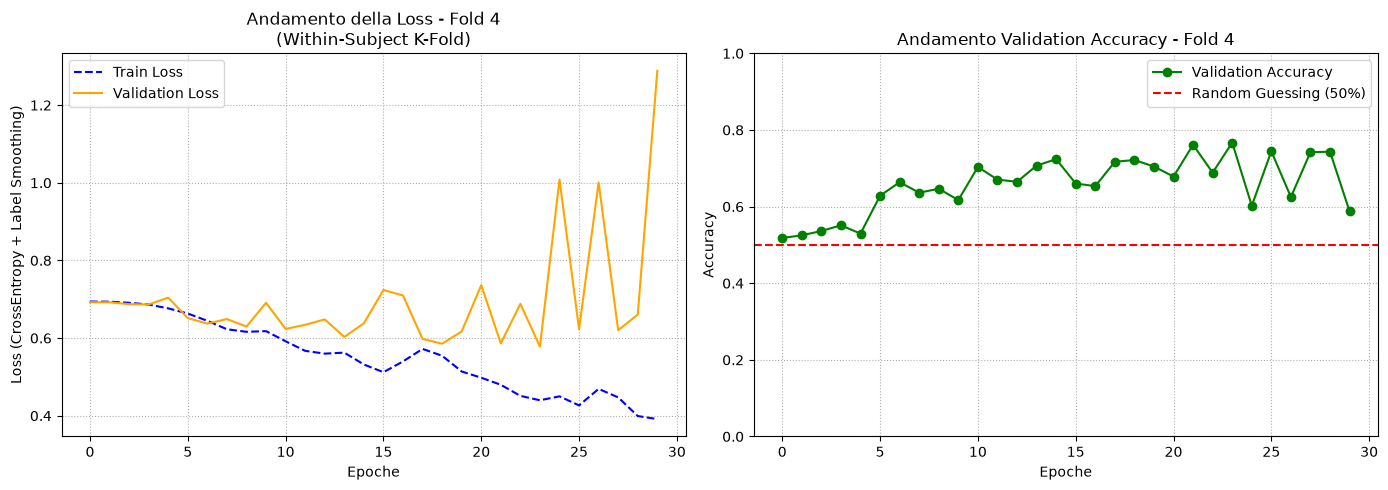


--- INIZIO TRAINING & VALIDAZIONE - FOLD 5/5 ---
Epoch 01/30: train_loss=0.69412, val_loss=0.69285, val_acc=49.77%
Epoch 02/30: train_loss=0.69454, val_loss=0.69238, val_acc=51.14%
Epoch 03/30: train_loss=0.69271, val_loss=0.69364, val_acc=49.77%
Epoch 04/30: train_loss=0.69078, val_loss=0.68767, val_acc=54.09%
Epoch 05/30: train_loss=0.68425, val_loss=0.67759, val_acc=55.11%
Epoch 06/30: train_loss=0.66957, val_loss=0.65552, val_acc=62.27%
Epoch 07/30: train_loss=0.65601, val_loss=0.64014, val_acc=62.95%
Epoch 08/30: train_loss=0.65369, val_loss=0.63730, val_acc=66.82%
Epoch 09/30: train_loss=0.64339, val_loss=0.62331, val_acc=66.93%
Epoch 10/30: train_loss=0.61624, val_loss=0.63651, val_acc=67.84%
Epoch 11/30: train_loss=0.59136, val_loss=0.65654, val_acc=66.48%
Epoch 12/30: train_loss=0.58793, val_loss=0.63848, val_acc=66.14%
Epoch 13/30: train_loss=0.58004, val_loss=0.70021, val_acc=67.50%
Epoch 14/30: train_loss=0.56876, val_loss=0.66795, val_acc=66.02%
Epoch 15/30: train_loss=0.

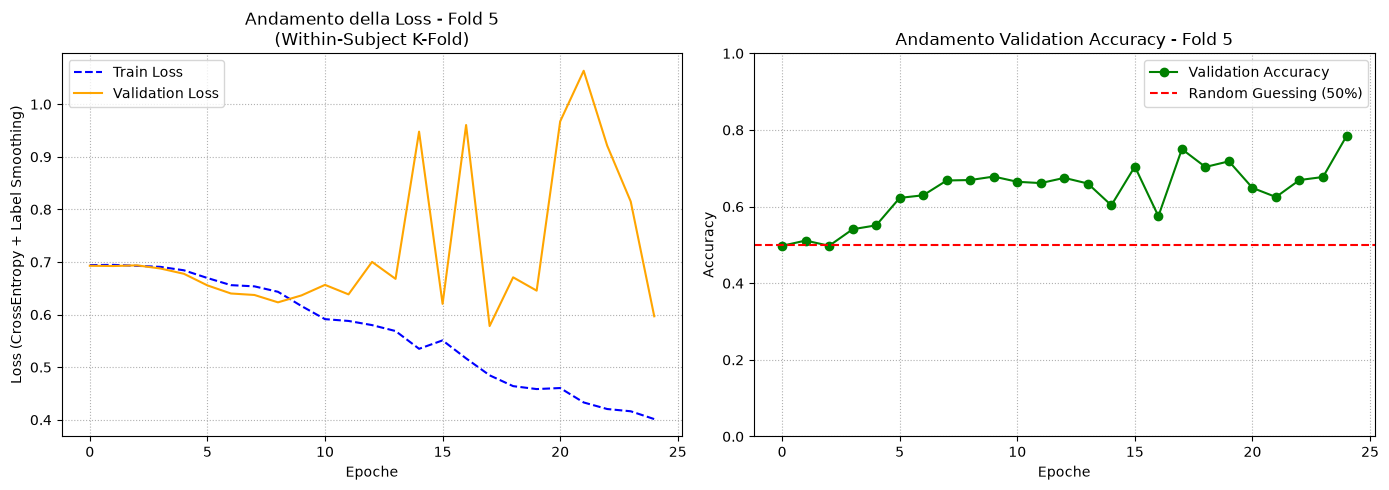


🎯 RISULTATO FINALE K-FOLD STANDARD (5 FOLD)
Accuracy media sui 5 fold: 76.40% (± 1.92%)
Validation Loss media: 0.7640


In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import KFold  # KFold standard (within-subject)
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# 2. Parametri di Configurazione
BATCH_SIZE = 64
EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 1e-3
ALPHA_NOISE = 0.01

# Inizializziamo KFold standard (split casuale dei trial)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

all_fold_best_accs = []
all_fold_best_losses = []

# ==========================================
# 3. CICLO DI TRAINING CON KFOLD STANDARD (WITHIN-SUBJECT)
# ==========================================
for fold, (train_idx, val_idx) in enumerate(kf.split(X_training_validation_raw, y_training_validation)):
    
    print(f"\n==========================================")
    print(f"--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 ---")
    print(f"==========================================")

    # A. Divisione dei dati grezzi in base al fold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=0.4, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore (AdamW), Loss (con Label Smoothing) e Scheduler (Cosine Annealing)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    # H. Inizializzazione della classe EEGTrainer
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )
    
    trainer.scheduler = scheduler

    # I. Avvio dell'addestramento
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS
    )

    max_fold_acc = max(val_accuracies)
    all_fold_best_accs.append(max_fold_acc)
    all_fold_best_losses.append(best_val_acc)

    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc:.4f} | Max Val Acc: {max_fold_acc*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE
    # ==========================================
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Fold {fold + 1}\n(Within-Subject K-Fold)')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

# ==========================================
# RISULTATO FINALE SUI 5 FOLD
# ==========================================
print(f"\n==========================================")
print(f"🎯 RISULTATO FINALE K-FOLD STANDARD (5 FOLD)")
print(f"==========================================")
print(f"Accuracy media sui 5 fold: {np.mean(all_fold_best_accs) * 100:.2f}% (± {np.std(all_fold_best_accs) * 100:.2f}%)")
print(f"Validation Loss media: {np.mean(all_fold_best_losses):.4f}")

### Codice completo


In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

param_grid = {
    'lr': [1e-3],
    'dropout': [0.5],
    'weight_decay': [1e-2],
}

NUM_TRIALS = 1

best_overall_acc = 0.0
best_overall_params = None

best_train_losses_history = None
best_val_losses_history = None
best_val_accs_history = None

# ==========================================
# 4. RANDOM SEARCH + GROUP K-FOLD CON NORMALIZZAZIONE PER-CANALE CORRETTA
# ==========================================
for trial in range(NUM_TRIALS):
    print(f'\n>>> RANDOM SEARCH - TENTATIVO {trial + 1}/{NUM_TRIALS} <<<\n')

    sampled_params = {key: random.choice(values) for key, values in param_grid.items()}
    print(f'Parametri testati: {sampled_params}')

    best_accuracies_per_fold = []
    trial_train_losses = []
    trial_val_losses = []
    trial_val_accs = []

    gkf = GroupKFold(n_splits=5)

    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        
        # A. Dividiamo i dati grezzi in base al fold
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        # B. CALCOLO MEDIA E STD PER-CANALE ESCLUSIVAMENTE SUL TRAINING SET
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
        epsilon = 1e-8
        alpha = 0.01

        # C. NORMALIZZAZIONE + RUMORE (DATA AUGMENTATION) SOLO SUL TRAIN
        X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
        noise = alpha * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise

        # D. NORMALIZZAZIONE PURA SUL VAL SET (Usando media e std del TRAIN, SENZA rumore!)
        X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

        # E. Creazione Dataset e DataLoader PyTorch
        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)

        train_loader =DataLoader(train_dataset, batch_size=64, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)


        model = EEGConformer(
            num_channels=64, 
            time_steps=641, 
            d_model=32, 
            nhead=4, 
            num_layers=1, 
            d_ff=128, 
            dropout=0.5, 
            num_classes=2
        ).to(device)

        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
        optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

        # Sfruttiamo il tuo trainer con Early Stopping integrato!
        trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

        # Lancia il training completo (si fermerà da solo quando la val_loss smette di migliorare)
        best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
            train_loader, val_loader, epochs=150
        )

        print(f'Miglior Val Accuracy Fold {fold + 1}: {best_val_acc * 100:.2f}%')

                # ==========================================
        # PLOT DELLE CURVE
        # ==========================================
        plt.figure(figsize=(14, 5))

        # Pannello 1: Loss
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
        plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
        plt.title('Andamento della Loss\n(MyEEGTransformer)')
        plt.xlabel('Epoche')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, linestyle=':')

        # Pannello 2: Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
        plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
        plt.title('Andamento Validation Accuracy')
        plt.xlabel('Epoche')
        plt.ylabel('Accuracy')
        plt.ylim(0.0, 1.0)
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.tight_layout()
        plt.show()

       

🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)

>>> RANDOM SEARCH - TENTATIVO 1/1 <<<

Parametri testati: {'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.01}
Epoch 01/150: train_loss=0.69445, val_loss=0.69425, val_acc=49.83%
Epoch 1: train_loss=0.69445, val_loss=0.69425,  val_accuracies=49.83%
Epoch 02/150: train_loss=0.69390, val_loss=0.69347, val_acc=48.90%
Epoch 2: train_loss=0.69390, val_loss=0.69347,  val_accuracies=48.90%
Epoch 03/150: train_loss=0.69267, val_loss=0.69278, val_acc=51.34%
Epoch 3: train_loss=0.69267, val_loss=0.69278,  val_accuracies=51.34%
Epoch 04/150: train_loss=0.69052, val_loss=0.68994, val_acc=53.89%
Epoch 4: train_loss=0.69052, val_loss=0.68994,  val_accuracies=53.89%
Epoch 05/150: train_loss=0.68299, val_loss=0.68096, val_acc=55.75%
Epoch 5: train_loss=0.68299, val_loss=0.68096,  val_accuracies=55.75%
Epoch 06/150: train_loss=0.68283, val_loss=0.67593, val_acc=55.40%
Epoch 6: train_loss=0.68283, val_loss=0.67593,  val_accuracies=55.40%
Epoch 07/150: train

KeyboardInterrupt: 

### 4. Model Definitions

Instantiate the Transformer-based models: s-Trans, t-Trans.


### 5. Training and Evaluation Functions



Implement the training and evaluation loops, including loss function, optimizer, and accuracy calculation. The paper uses Adam optimizer and cross-entropy loss.

### 6. Cross-Individual 5-Fold Cross-Validation



Implement the 5-fold cross-validation strategy as described in the paper. This involves splitting subjects into training and testing sets.

### 7. Positional Embedding Analysis (Visualization)



This section would involve analyzing the impact of different positional embedding methods on model performance, as discussed in the paper. This would be derived from the cross-validation results.

### 8. Attention Weight Visualization




Visualize the attention weights from the Transformer modules, especially for the s-Trans model, to understand the model"s focus on different EEG channels, similar to the topographical analysis in the paper (Fig. 6). This requires mne.viz.plot_topomap and electrode location information.


# GroupKFold + grid search solo su primo fold

In [1]:
import itertools
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# ==========================================
# 1. CONFIGURAZIONE DEL DISPOSITIVO
# ==========================================
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# ==========================================
# 2. PARAMETRI GENERALI E GRID SEARCH
# ==========================================
BATCH_SIZE = 64
ALPHA_NOISE = 0.01

# Definizione dello spazio degli iperparametri da testare
param_grid = {
    'lr': [1e-3, 1e-4],
    'dropout': [0.3, 0.5],
    'weight_decay': [1e-3, 1e-2]
}

keys = param_grid.keys()
combinations = [dict(zip(keys, prod)) for prod in itertools.product(*param_grid.values())]

gkf = GroupKFold(n_splits=5)

print(f"\n🧪 Spazio Grid Search definito: {len(combinations)} combinazioni da testare.")

# Estraiamo il primo fold di gruppo come riferimento per il tuning degli iperparametri
for train_idx, val_idx in gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation):
    X_train_t_raw = X_training_validation_raw[train_idx]
    y_train_t = y_training_validation[train_idx]
    X_val_t_raw = X_training_validation_raw[val_idx]
    y_val_t = y_training_validation[val_idx]
    break  # Ci basta il primo split per trovare i parametri

# Normalizzazione preliminare per il tuning
t_mean = np.mean(X_train_t_raw, axis=(0, 2), keepdims=True)  
t_std = np.std(X_train_t_raw, axis=(0, 2), keepdims=True)
epsilon = 1e-8

X_train_t_norm = (X_train_t_raw - t_mean) / (t_std + epsilon)
X_train_t_final = X_train_t_norm + (ALPHA_NOISE * np.random.randn(*X_train_t_norm.shape))
X_val_t_final = (X_val_t_raw - t_mean) / (t_std + epsilon)

train_loader_grid = DataLoader(EEGDataset(X_train_t_final, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader_grid = DataLoader(EEGDataset(X_val_t_final, y_val_t), batch_size=BATCH_SIZE, shuffle=False)

best_overall_acc = 0.0
best_hyperparams = None
TUNING_EPOCHS = 30  

print("\n==========================================")
print("🔍 INIZIO GRID SEARCH (CROSS-SUBJECT)")
print("==========================================")

for i, params in enumerate(combinations):
    print(f"Test {i+1}/{len(combinations)} | LR: {params['lr']} | Dropout: {params['dropout']} | WD: {params['weight_decay']}")
    
    model_t = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=params['dropout'], num_classes=2
    ).to(device)
    
    criterion_t = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer_t = optim.AdamW(model_t.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
    scheduler_t = optim.lr_scheduler.CosineAnnealingLR(optimizer_t, T_max=TUNING_EPOCHS, eta_min=1e-6)

    trainer_t = EEGTrainer(model=model_t, criterion=criterion_t, optimizer=optimizer_t, device=device)
    trainer_t.scheduler = scheduler_t

    _, _, _, val_accs_t = trainer_t.train_and_validate(
        train_loader=train_loader_grid, val_loader=val_loader_grid, epochs=TUNING_EPOCHS
    )

    current_max_acc = max(val_accs_t)
    if current_max_acc > best_overall_acc:
        best_overall_acc = current_max_acc
        best_hyperparams = params
        print(f"🎉 Nuovo record provvisorio! Max Accuracy: {best_overall_acc * 100:.2f}%")

print(f"\n🏆 CONFIGURAZIONE VINCENTE TROVATA DALLA GRID SEARCH:")
print(f"   - Parametri: {best_hyperparams}")
print(f"   - Max Accuracy di Tuning: {best_overall_acc * 100:.2f}%\n")



🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

🧪 Spazio Grid Search definito: 8 combinazioni da testare.


NameError: name 'X_training_validation_raw' is not defined

🚀 INIZIO CROSS-VALIDATION 5-FOLD COMPLETA CON I PARAMETRI OTTIMALI

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 (Cross-Subject) ---
Epoch 01/30: train_loss=0.69454, val_loss=0.69342, val_acc=49.83%
Epoch 02/30: train_loss=0.69179, val_loss=0.69370, val_acc=50.52%
Epoch 03/30: train_loss=0.69029, val_loss=0.68965, val_acc=52.26%
Epoch 04/30: train_loss=0.68126, val_loss=0.70955, val_acc=51.45%
Epoch 05/30: train_loss=0.66907, val_loss=0.74151, val_acc=50.64%
Epoch 06/30: train_loss=0.64921, val_loss=0.70412, val_acc=56.21%
Epoch 07/30: train_loss=0.64735, val_loss=0.66896, val_acc=58.65%
Epoch 08/30: train_loss=0.62036, val_loss=0.68801, val_acc=59.81%
Epoch 09/30: train_loss=0.60484, val_loss=0.65429, val_acc=61.67%
Epoch 10/30: train_loss=0.57817, val_loss=0.67029, val_acc=63.18%
Epoch 11/30: train_loss=0.55307, val_loss=0.65228, val_acc=65.62%
Epoch 12/30: train_loss=0.54713, val_loss=0.61939, val_acc=71.08%
Epoch 13/30: train_loss=0.53134, val_loss=0.73204, val_acc=64.11%
Epoch 14/

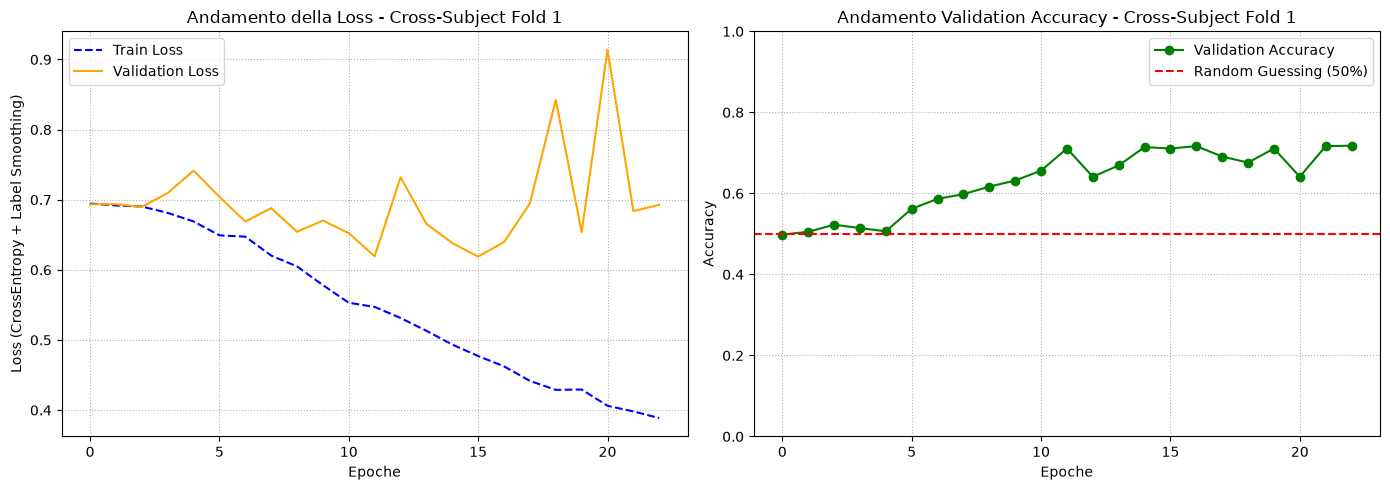


--- INIZIO TRAINING & VALIDAZIONE - FOLD 2/5 (Cross-Subject) ---
Epoch 01/30: train_loss=0.69622, val_loss=0.69304, val_acc=49.94%
Epoch 02/30: train_loss=0.69342, val_loss=0.69293, val_acc=50.29%
Epoch 03/30: train_loss=0.69018, val_loss=0.69053, val_acc=50.75%
Epoch 04/30: train_loss=0.67809, val_loss=0.68930, val_acc=54.12%
Epoch 05/30: train_loss=0.66142, val_loss=0.68697, val_acc=57.84%
Epoch 06/30: train_loss=0.64287, val_loss=0.66500, val_acc=60.74%
Epoch 07/30: train_loss=0.62771, val_loss=0.64581, val_acc=66.32%
Epoch 08/30: train_loss=0.60405, val_loss=0.68217, val_acc=63.53%
Epoch 09/30: train_loss=0.58353, val_loss=0.65704, val_acc=67.02%
Epoch 10/30: train_loss=0.56738, val_loss=0.67841, val_acc=62.37%
Epoch 11/30: train_loss=0.54095, val_loss=0.61681, val_acc=68.06%
Epoch 12/30: train_loss=0.52947, val_loss=0.81825, val_acc=59.81%
Epoch 13/30: train_loss=0.51161, val_loss=0.77056, val_acc=62.25%
Epoch 14/30: train_loss=0.49843, val_loss=0.69096, val_acc=67.71%
Epoch 15/3

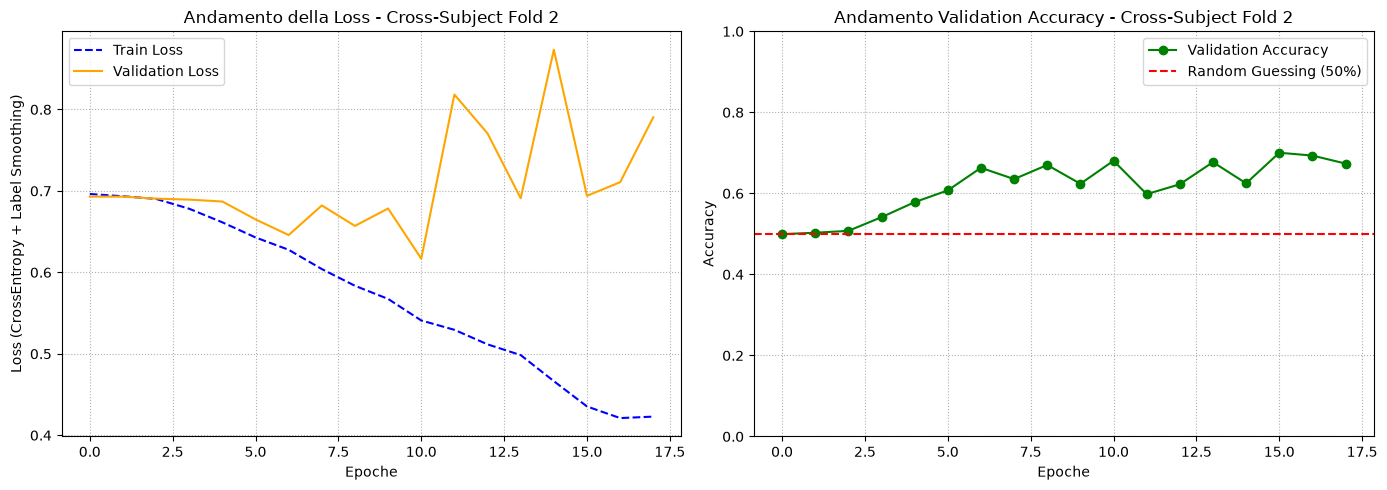


--- INIZIO TRAINING & VALIDAZIONE - FOLD 3/5 (Cross-Subject) ---
Epoch 01/30: train_loss=0.69466, val_loss=0.69253, val_acc=50.56%
Epoch 02/30: train_loss=0.69448, val_loss=0.69287, val_acc=49.44%
Epoch 03/30: train_loss=0.69363, val_loss=0.69289, val_acc=50.34%
Epoch 04/30: train_loss=0.69287, val_loss=0.68915, val_acc=53.36%
Epoch 05/30: train_loss=0.69204, val_loss=0.68677, val_acc=50.56%
Epoch 06/30: train_loss=0.68973, val_loss=0.67878, val_acc=56.84%
Epoch 07/30: train_loss=0.68280, val_loss=0.65103, val_acc=62.22%
Epoch 08/30: train_loss=0.66991, val_loss=0.65314, val_acc=59.42%
Epoch 09/30: train_loss=0.65341, val_loss=0.61850, val_acc=66.26%
Epoch 10/30: train_loss=0.62398, val_loss=0.60095, val_acc=67.83%
Epoch 11/30: train_loss=0.60337, val_loss=0.65260, val_acc=64.91%
Epoch 12/30: train_loss=0.58628, val_loss=0.58236, val_acc=70.40%
Epoch 13/30: train_loss=0.56552, val_loss=0.66225, val_acc=67.94%
Epoch 14/30: train_loss=0.54013, val_loss=0.67921, val_acc=66.37%
Epoch 15/3

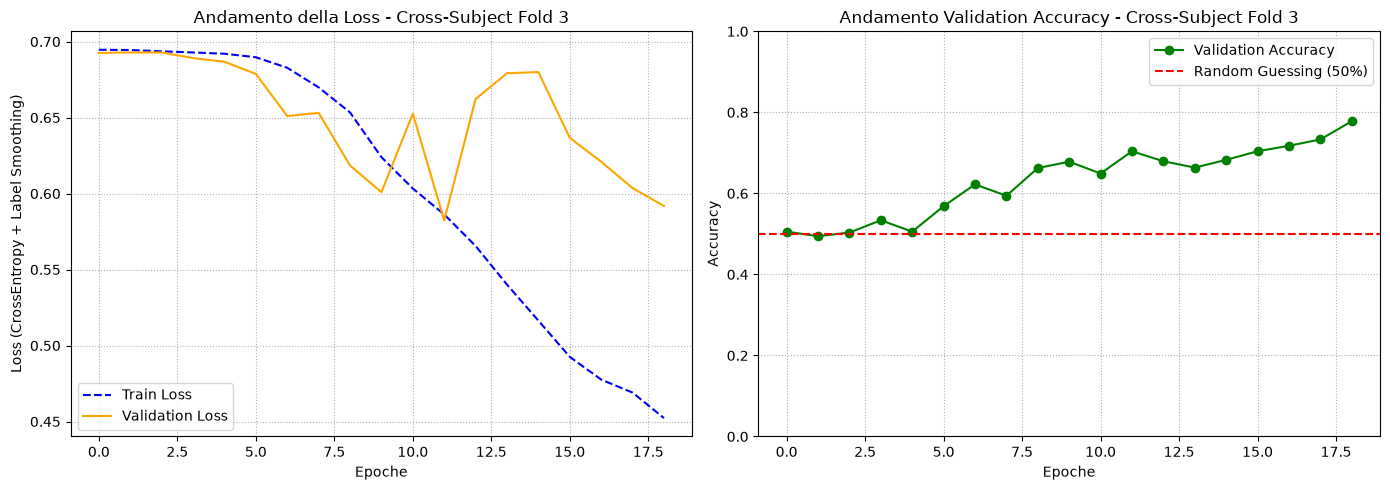


--- INIZIO TRAINING & VALIDAZIONE - FOLD 4/5 (Cross-Subject) ---
Epoch 01/30: train_loss=0.69695, val_loss=0.69527, val_acc=49.55%
Epoch 02/30: train_loss=0.69524, val_loss=0.69149, val_acc=54.81%
Epoch 03/30: train_loss=0.69341, val_loss=0.69198, val_acc=49.55%
Epoch 04/30: train_loss=0.68512, val_loss=0.72069, val_acc=55.03%
Epoch 05/30: train_loss=0.66966, val_loss=0.74164, val_acc=60.74%
Epoch 06/30: train_loss=0.64275, val_loss=0.69742, val_acc=64.09%
Epoch 07/30: train_loss=0.62448, val_loss=0.85061, val_acc=54.59%
Epoch 08/30: train_loss=0.61537, val_loss=0.73329, val_acc=59.84%
Epoch 09/30: train_loss=0.59860, val_loss=0.69694, val_acc=61.74%
Early stopping all'epoca 9
✅ Fold 4 completato | Min Val Loss: 0.6915 | Max Val Acc: 64.09%


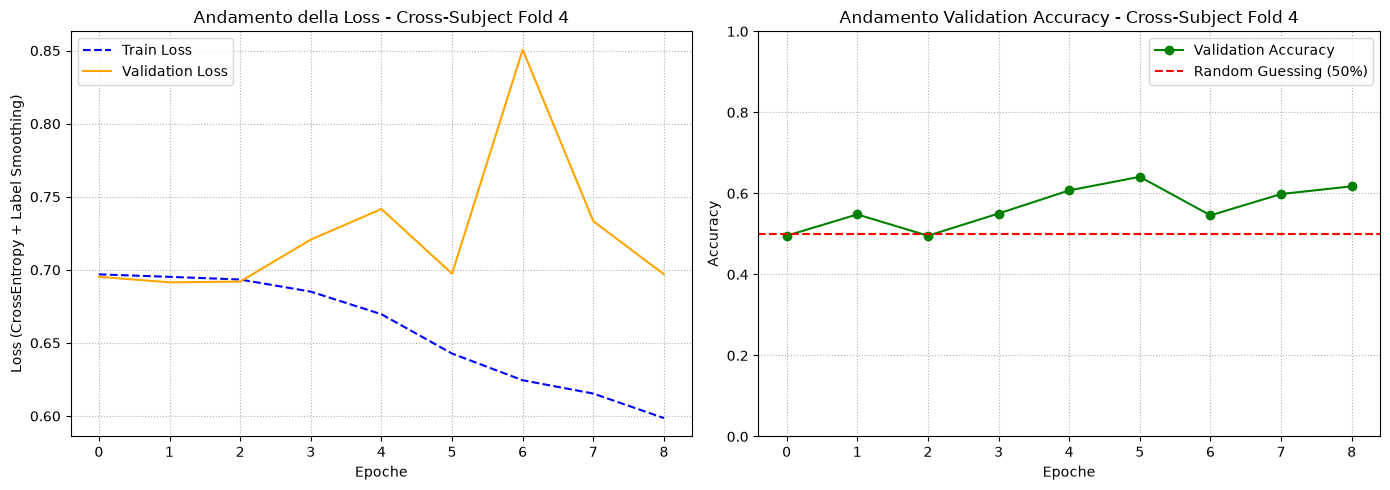


--- INIZIO TRAINING & VALIDAZIONE - FOLD 5/5 (Cross-Subject) ---
Epoch 01/30: train_loss=0.69413, val_loss=0.69206, val_acc=52.57%
Epoch 02/30: train_loss=0.69106, val_loss=0.69016, val_acc=53.24%
Epoch 03/30: train_loss=0.68872, val_loss=0.68812, val_acc=55.82%
Epoch 04/30: train_loss=0.67933, val_loss=0.67062, val_acc=57.38%
Epoch 05/30: train_loss=0.66480, val_loss=0.68571, val_acc=56.94%
Epoch 06/30: train_loss=0.64282, val_loss=0.75010, val_acc=54.36%
Epoch 07/30: train_loss=0.62657, val_loss=0.72672, val_acc=55.37%
Epoch 08/30: train_loss=0.61284, val_loss=0.63609, val_acc=66.67%
Epoch 09/30: train_loss=0.58155, val_loss=0.75921, val_acc=62.30%
Epoch 10/30: train_loss=0.57020, val_loss=0.65466, val_acc=67.90%
Epoch 11/30: train_loss=0.54276, val_loss=0.77541, val_acc=59.17%
Epoch 12/30: train_loss=0.53050, val_loss=0.63775, val_acc=71.14%
Epoch 13/30: train_loss=0.50771, val_loss=0.65501, val_acc=68.34%
Epoch 14/30: train_loss=0.48408, val_loss=0.64661, val_acc=73.49%
Epoch 15/3

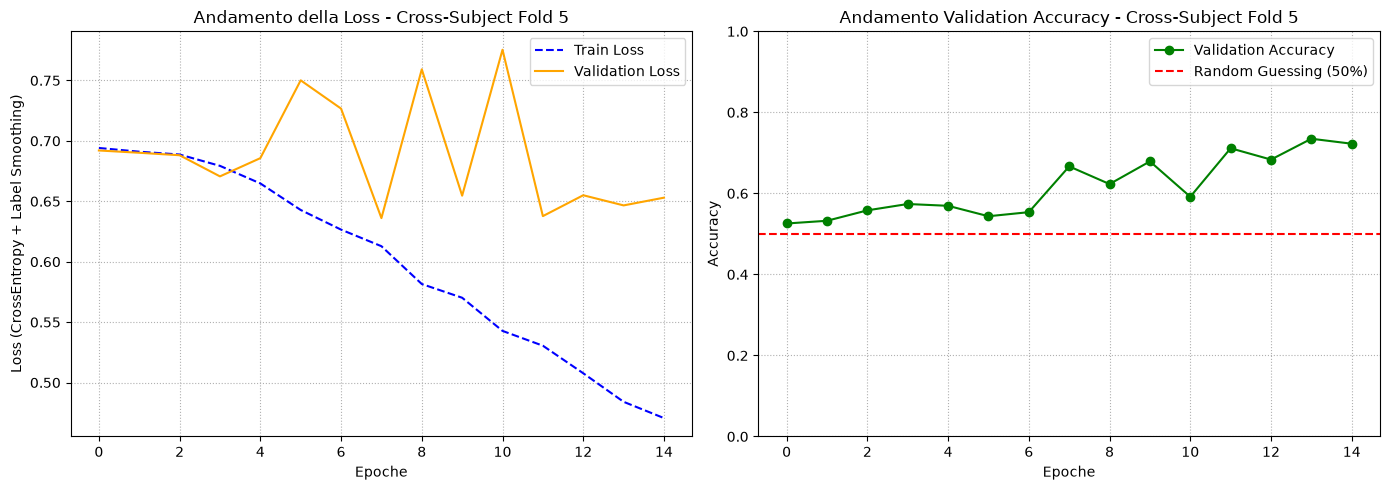


🎯 RISULTATO FINALE CROSS-SUBJECT (GROUP K-FOLD)
Accuracy media sui 5 fold: 71.44% (± 4.49%)
Validation Loss media (minima): 0.6291


In [ ]:

# ==========================================
# 3. CICLO DI CROSS-VALIDATION COMPLETO (5 FOLD - GROUP K-FOLD)
# ==========================================
EPOCHS = 30
all_fold_best_accs = []
all_fold_best_losses = []

print("==========================================")
print("🚀 INIZIO CROSS-VALIDATION 5-FOLD COMPLETA CON I PARAMETRI OTTIMALI")
print("==========================================")

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 (Cross-Subject) ---")

    # A. Divisione dei dati grezzi in base al fold del GroupKFold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set (Prevenzione Data Leakage)
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer con i parametri vincenti della Grid Search
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, 
        dropout=best_hyperparams['dropout'], num_classes=2
    ).to(device)
    
    # G. Ottimizzatore, Loss e Scheduler configurati con i iperparametri ottimali
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=best_hyperparams['lr'], weight_decay=best_hyperparams['weight_decay'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    # H. Inizializzazione della classe EEGTrainer
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )
    trainer.scheduler = scheduler

    # I. Avvio dell'addestramento tramite il metodo della classe
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    max_fold_acc = max(val_accuracies)
    min_fold_loss = min(val_losses)
    
    all_fold_best_accs.append(max_fold_acc)
    all_fold_best_losses.append(min_fold_loss)

    print(f"✅ Fold {fold + 1} completato | Min Val Loss: {min_fold_loss:.4f} | Max Val Acc: {max_fold_acc*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
    # ==========================================
    plt.figure(figsize=(14, 5))

    # Pannello 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Cross-Subject Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Pannello 2:
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Cross-Subject Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

# ==========================================
# 4. RISULTATO FINALE COMPLESSIVO
# ==========================================
print(f"\n==========================================")
print(f"🎯 RISULTATO FINALE CROSS-SUBJECT (GROUP K-FOLD)")
print(f"==========================================")
print(f"Accuracy media sui 5 fold: {np.mean(all_fold_best_accs) * 100:.2f}% (± {np.std(all_fold_best_accs) * 100:.2f}%)")
print(f"Validation Loss media (minima): {np.mean(all_fold_best_losses):.4f}")

# KFold con best iperparametri grid search di gfk


🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 ---
Epoch 01/30: train_loss=0.69451, val_loss=0.69602, val_acc=48.35%
Epoch 02/30: train_loss=0.69444, val_loss=0.69165, val_acc=53.35%
Epoch 03/30: train_loss=0.69230, val_loss=0.68924, val_acc=55.16%
Epoch 04/30: train_loss=0.68938, val_loss=0.68174, val_acc=58.00%
Epoch 05/30: train_loss=0.67769, val_loss=0.68350, val_acc=58.23%
Epoch 06/30: train_loss=0.65478, val_loss=0.70313, val_acc=55.16%
Epoch 07/30: train_loss=0.63787, val_loss=0.68139, val_acc=58.91%
Epoch 08/30: train_loss=0.61946, val_loss=0.66279, val_acc=63.90%
Epoch 09/30: train_loss=0.60271, val_loss=0.67282, val_acc=63.11%
Epoch 10/30: train_loss=0.60454, val_loss=0.64745, val_acc=64.93%
Epoch 11/30: train_loss=0.59544, val_loss=0.61810, val_acc=67.54%
Epoch 12/30: train_loss=0.56225, val_loss=0.60018, val_acc=70.94%
Epoch 13/30: train_loss=0.57045, val_loss=0.60857, val_acc=69.81%
Epoch 14/30: train_loss=0.57057, val_loss=0.63129,

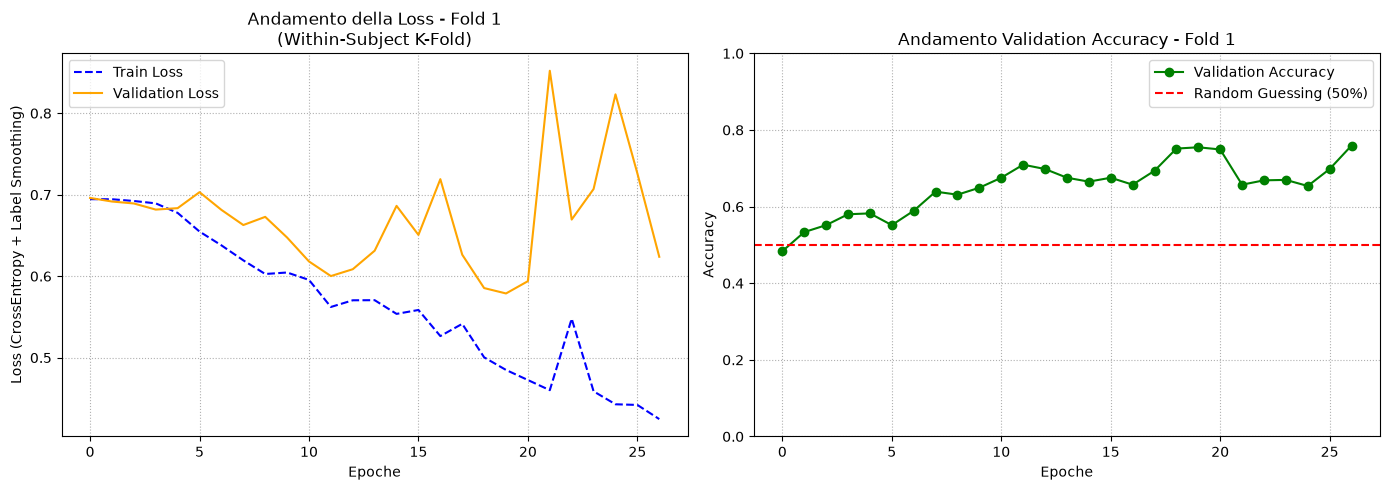


--- INIZIO TRAINING & VALIDAZIONE - FOLD 2/5 ---
Epoch 01/30: train_loss=0.69639, val_loss=0.69419, val_acc=49.15%
Epoch 02/30: train_loss=0.69362, val_loss=0.69215, val_acc=51.76%
Epoch 03/30: train_loss=0.69386, val_loss=0.69120, val_acc=49.38%
Epoch 04/30: train_loss=0.68603, val_loss=0.71838, val_acc=48.92%
Epoch 05/30: train_loss=0.69363, val_loss=0.67634, val_acc=57.09%
Epoch 06/30: train_loss=0.66882, val_loss=0.69888, val_acc=56.19%
Epoch 07/30: train_loss=0.66458, val_loss=0.66718, val_acc=57.32%
Epoch 08/30: train_loss=0.64844, val_loss=0.74387, val_acc=54.48%
Epoch 09/30: train_loss=0.65686, val_loss=0.66419, val_acc=57.21%
Epoch 10/30: train_loss=0.63536, val_loss=0.63536, val_acc=66.06%
Epoch 11/30: train_loss=0.62393, val_loss=0.61540, val_acc=66.06%
Epoch 12/30: train_loss=0.59868, val_loss=0.61798, val_acc=66.52%
Epoch 13/30: train_loss=0.59225, val_loss=0.61050, val_acc=69.24%
Epoch 14/30: train_loss=0.60182, val_loss=0.59984, val_acc=69.81%
Epoch 15/30: train_loss=0.

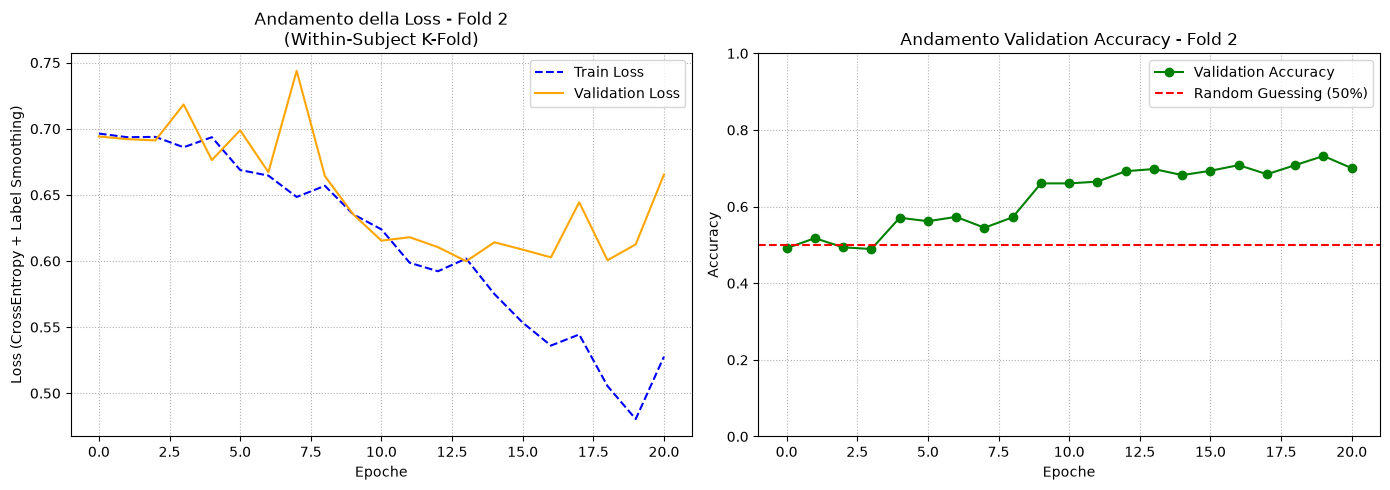


--- INIZIO TRAINING & VALIDAZIONE - FOLD 3/5 ---
Epoch 01/30: train_loss=0.69331, val_loss=0.69161, val_acc=53.07%
Epoch 02/30: train_loss=0.69480, val_loss=0.69099, val_acc=53.52%
Epoch 03/30: train_loss=0.69153, val_loss=0.69121, val_acc=51.14%
Epoch 04/30: train_loss=0.68567, val_loss=0.69890, val_acc=49.43%
Epoch 05/30: train_loss=0.67614, val_loss=0.67457, val_acc=58.07%
Epoch 06/30: train_loss=0.67133, val_loss=0.67567, val_acc=55.34%
Epoch 07/30: train_loss=0.65806, val_loss=0.64730, val_acc=63.30%
Epoch 08/30: train_loss=0.65572, val_loss=0.63117, val_acc=63.75%
Epoch 09/30: train_loss=0.62248, val_loss=0.63405, val_acc=65.57%
Epoch 10/30: train_loss=0.60149, val_loss=0.61551, val_acc=68.98%
Epoch 11/30: train_loss=0.60475, val_loss=0.62485, val_acc=66.36%
Epoch 12/30: train_loss=0.59020, val_loss=0.61705, val_acc=69.77%
Epoch 13/30: train_loss=0.56421, val_loss=0.59057, val_acc=73.75%
Epoch 14/30: train_loss=0.55211, val_loss=0.57605, val_acc=73.30%
Epoch 15/30: train_loss=0.

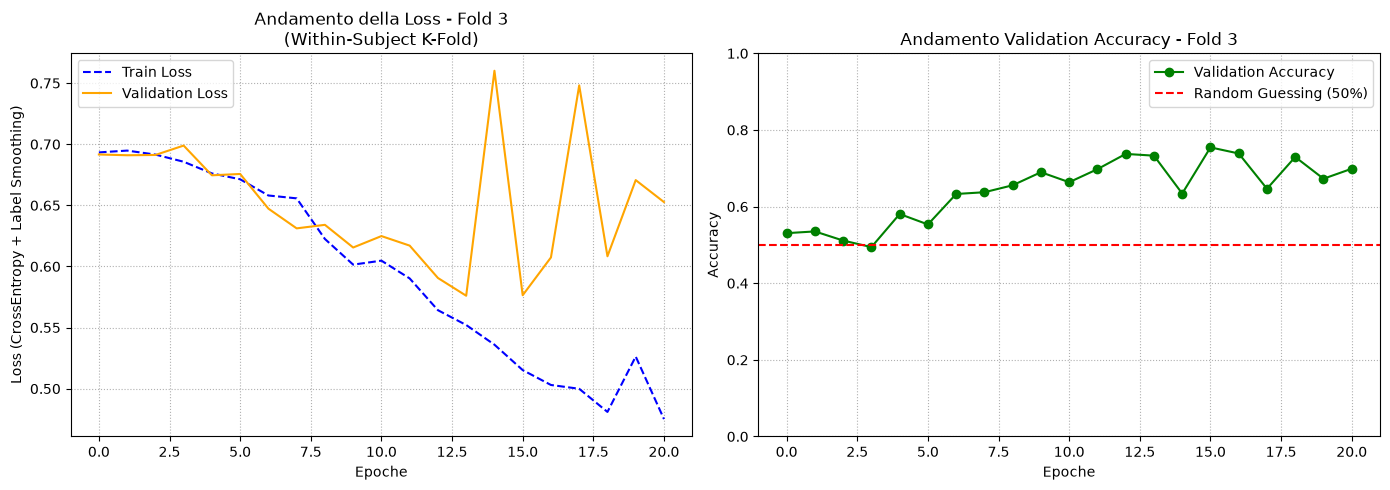


--- INIZIO TRAINING & VALIDAZIONE - FOLD 4/5 ---
Epoch 01/30: train_loss=0.69413, val_loss=0.69351, val_acc=49.66%
Epoch 02/30: train_loss=0.69255, val_loss=0.69166, val_acc=54.55%
Epoch 03/30: train_loss=0.69014, val_loss=0.68248, val_acc=57.27%
Epoch 04/30: train_loss=0.68202, val_loss=0.66990, val_acc=57.05%
Epoch 05/30: train_loss=0.67253, val_loss=0.66491, val_acc=59.32%
Epoch 06/30: train_loss=0.65963, val_loss=0.65715, val_acc=62.05%
Epoch 07/30: train_loss=0.63536, val_loss=0.64475, val_acc=62.95%
Epoch 08/30: train_loss=0.62566, val_loss=0.63466, val_acc=65.45%
Epoch 09/30: train_loss=0.62179, val_loss=0.64405, val_acc=66.93%
Epoch 10/30: train_loss=0.60384, val_loss=0.60443, val_acc=68.98%
Epoch 11/30: train_loss=0.57060, val_loss=0.65817, val_acc=65.45%
Epoch 12/30: train_loss=0.57043, val_loss=0.64055, val_acc=66.02%
Epoch 13/30: train_loss=0.55525, val_loss=0.59443, val_acc=70.34%
Epoch 14/30: train_loss=0.54686, val_loss=0.61839, val_acc=68.75%
Epoch 15/30: train_loss=0.

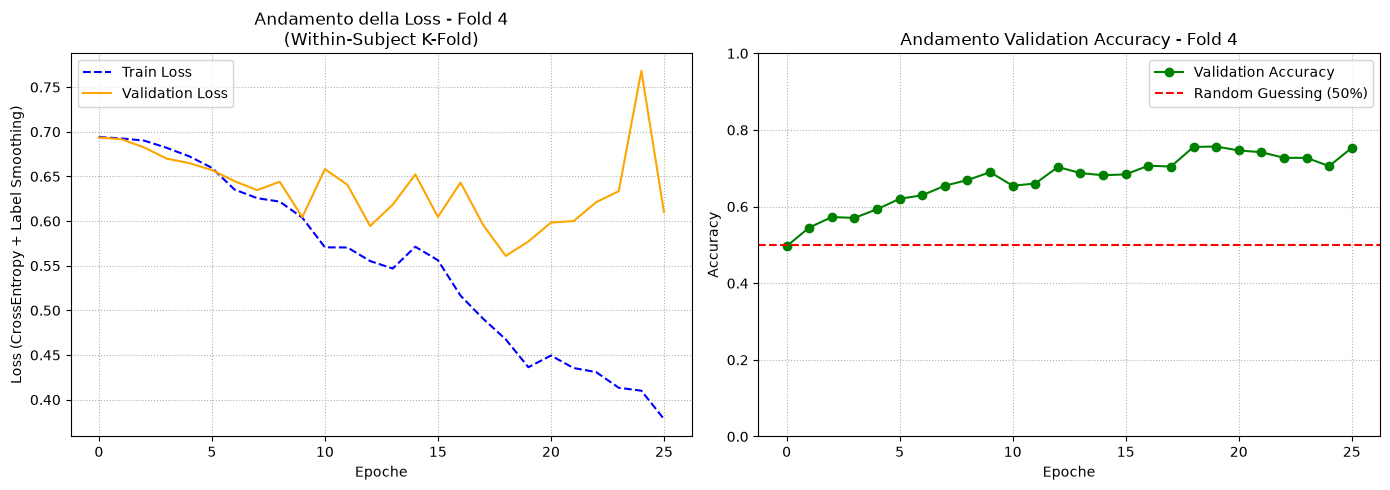


--- INIZIO TRAINING & VALIDAZIONE - FOLD 5/5 ---
Epoch 01/30: train_loss=0.69460, val_loss=0.69230, val_acc=49.55%
Epoch 02/30: train_loss=0.69203, val_loss=0.68989, val_acc=50.80%
Epoch 03/30: train_loss=0.68820, val_loss=0.68066, val_acc=56.59%
Epoch 04/30: train_loss=0.68095, val_loss=0.68207, val_acc=55.00%
Epoch 05/30: train_loss=0.66410, val_loss=0.67770, val_acc=59.20%
Epoch 06/30: train_loss=0.65228, val_loss=0.63377, val_acc=63.30%
Epoch 07/30: train_loss=0.64019, val_loss=0.61461, val_acc=70.45%
Epoch 08/30: train_loss=0.62602, val_loss=0.62925, val_acc=65.11%
Epoch 09/30: train_loss=0.60087, val_loss=0.59874, val_acc=73.75%
Epoch 10/30: train_loss=0.57685, val_loss=0.61231, val_acc=70.45%
Epoch 11/30: train_loss=0.55735, val_loss=0.61400, val_acc=70.00%
Epoch 12/30: train_loss=0.53734, val_loss=0.71460, val_acc=63.64%
Epoch 13/30: train_loss=0.52620, val_loss=0.65565, val_acc=68.18%
Epoch 14/30: train_loss=0.51326, val_loss=0.61630, val_acc=70.80%
Epoch 15/30: train_loss=0.

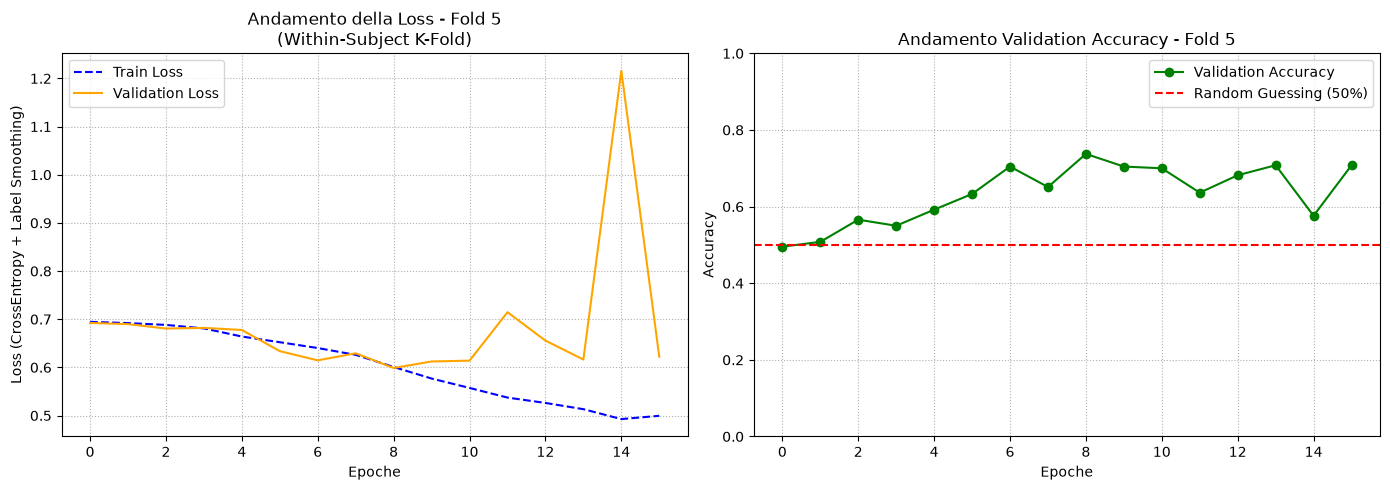


🎯 RISULTATO FINALE K-FOLD STANDARD (5 FOLD)
Accuracy media sui 5 fold: 74.81% (± 1.11%)
Validation Loss media: 0.7481


In [16]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import KFold  # KFold standard (within-subject)
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# 2. Parametri di Configurazione
BATCH_SIZE = 64
EPOCHS = 30
LR = 0.001
WEIGHT_DECAY = 0.001
ALPHA_NOISE = 0.01

# Inizializziamo KFold standard (split casuale dei trial)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

all_fold_best_accs = []
all_fold_best_losses = []

# ==========================================
# 3. CICLO DI TRAINING CON KFOLD STANDARD (WITHIN-SUBJECT)
# ==========================================
for fold, (train_idx, val_idx) in enumerate(kf.split(X_training_validation_raw, y_training_validation)):
    
    print(f"\n==========================================")
    print(f"--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 ---")
    print(f"==========================================")

    # A. Divisione dei dati grezzi in base al fold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=0.3, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore (AdamW), Loss (con Label Smoothing) e Scheduler (Cosine Annealing)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    # H. Inizializzazione della classe EEGTrainer
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )
    
    trainer.scheduler = scheduler

    # I. Avvio dell'addestramento
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS
    )

    max_fold_acc = max(val_accuracies)
    all_fold_best_accs.append(max_fold_acc)
    all_fold_best_losses.append(best_val_acc)

    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc:.4f} | Max Val Acc: {max_fold_acc*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE
    # ==========================================
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Fold {fold + 1}\n(Within-Subject K-Fold)')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

# ==========================================
# RISULTATO FINALE SUI 5 FOLD
# ==========================================
print(f"\n==========================================")
print(f"🎯 RISULTATO FINALE K-FOLD STANDARD (5 FOLD)")
print(f"==========================================")
print(f"Accuracy media sui 5 fold: {np.mean(all_fold_best_accs) * 100:.2f}% (± {np.std(all_fold_best_accs) * 100:.2f}%)")
print(f"Validation Loss media: {np.mean(all_fold_best_losses):.4f}")

# GroupKFold con gridsearch su tutti i fold

In [9]:
import itertools
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold

# ==========================================
# 1. CONFIGURAZIONE DEL GRIGLIA E DELLO STRUMENTO
# ==========================================
param_grid = {
    'lr': [1e-3, 1e-4],
    'dropout': [0.3,0.4, 0.5],
    'weight_decay': [1e-3, 1e-2]
}

keys = param_grid.keys()
combinations = [dict(zip(keys, prod)) for prod in itertools.product(*param_grid.values())]

gkf = GroupKFold(n_splits=5)
TUNING_EPOCHS = 20  # Epoche ridotte per velocizzare la valutazione sui 5 fold
BATCH_SIZE = 64
ALPHA_NOISE = 0.01
epsilon = 1e-8

print(f"\n🧪 Spazio Grid Search: {len(combinations)} combinazioni da valutare su TUTTI i 5 Fold.")

best_overall_mean_acc = 0.0
best_hyperparams = None

# ==========================================
# 2. CICLO DI TUNING SUI 5 FOLD
# ==========================================
print("\n==========================================")
print("🔍 INIZIO GRID SEARCH 5-FOLD CROSS-VALIDATION")
print("==========================================")

for i, params in enumerate(combinations):
    print(f"\n--- Test Combinazione {i+1}/{len(combinations)} | LR: {params['lr']} | Dropout: {params['dropout']} | WD: {params['weight_decay']} ---")
    
    fold_max_accs = []
    
    # Eseguiamo i 5 fold per questa specifica combinazione
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        # Normalizzazione esclusiva sul training set del fold corrente (Prevenzione Data Leakage)
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

        X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
        X_train_final = X_train_norm + (ALPHA_NOISE * np.random.randn(*X_train_norm.shape))
        X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

        # DataLoader
        train_loader_t = DataLoader(EEGDataset(X_train_final, y_train), batch_size=BATCH_SIZE, shuffle=True)
        val_loader_t = DataLoader(EEGDataset(X_val_final, y_val), batch_size=BATCH_SIZE, shuffle=False)

        # Modello con i parametri correnti del test
        model_t = EEGConformer(
            num_channels=64, time_steps=641, d_model=32, 
            nhead=4, num_layers=1, d_ff=128, dropout=params['dropout'], num_classes=2
        ).to(device)
        
        criterion_t = nn.CrossEntropyLoss(label_smoothing=0.1)
        optimizer_t = optim.AdamW(model_t.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
        scheduler_t = optim.lr_scheduler.CosineAnnealingLR(optimizer_t, T_max=TUNING_EPOCHS, eta_min=1e-6)

        trainer_t = EEGTrainer(model=model_t, criterion=criterion_t, optimizer=optimizer_t, device=device)
        trainer_t.scheduler = scheduler_t

        # Training rapido sul fold
        _, _, _, val_accs_t = trainer_t.train_and_validate(
            train_loader=train_loader_t, val_loader=val_loader_t, epochs=TUNING_EPOCHS
        )

        fold_max_accs.append(max(val_accs_t))

    # Calcoliamo l'accuracy media sui 5 fold per questa combinazione
    mean_accuracy = np.mean(fold_max_accs)
    print(f"👉 Media Accuracy sui 5 fold: {mean_accuracy * 100:.2f}% (Singoli fold: {[f'{acc*100:.1f}%' for acc in fold_max_accs]})")

    # Aggiorniamo il record se questa combinazione batte la precedente
    if mean_accuracy > best_overall_mean_acc:
        best_overall_mean_acc = mean_accuracy
        best_hyperparams = params
        print(f"🎉 Nuovo record globale! Miglior Media: {best_overall_mean_acc * 100:.2f}%")

# ==========================================
# 3. RISULTATO FINALE DEL TUNING
# ==========================================
print(f"\n==========================================")
print(f"🏆 CONFIGURAZIONE VINCENTE DELLA GRID SEARCH:")
print(f"==========================================")
print(f"   - Iperparametri ottimali: {best_hyperparams}")
print(f"   - Media Accuracy di Cross-Validation: {best_overall_mean_acc * 100:.2f}%")
print(f"==========================================")


🧪 Spazio Grid Search: 12 combinazioni da valutare su TUTTI i 5 Fold.

🔍 INIZIO GRID SEARCH 5-FOLD CROSS-VALIDATION

--- Test Combinazione 1/12 | LR: 0.001 | Dropout: 0.3 | WD: 0.001 ---
Epoch 01/20: train_loss=0.69480, val_loss=0.69475, val_acc=50.17%
Epoch 02/20: train_loss=0.69338, val_loss=0.69292, val_acc=50.17%
Epoch 03/20: train_loss=0.69213, val_loss=0.69284, val_acc=50.29%
Epoch 04/20: train_loss=0.68728, val_loss=0.68515, val_acc=53.19%
Epoch 05/20: train_loss=0.68139, val_loss=0.68184, val_acc=55.05%
Epoch 06/20: train_loss=0.66413, val_loss=0.66662, val_acc=57.38%
Epoch 07/20: train_loss=0.63217, val_loss=0.67775, val_acc=57.03%
Epoch 08/20: train_loss=0.61412, val_loss=0.66693, val_acc=62.72%
Epoch 09/20: train_loss=0.60945, val_loss=0.75975, val_acc=54.94%
Epoch 10/20: train_loss=0.59301, val_loss=0.63704, val_acc=66.20%
Epoch 11/20: train_loss=0.57441, val_loss=0.69883, val_acc=63.18%
Epoch 12/20: train_loss=0.56316, val_loss=0.64108, val_acc=68.41%
Epoch 13/20: train_lo

ho salvato solo i valori dell'accuracy oer salvare spaizoe e tempo


🚀 AVVIO TRAINING FINALE SUI 5 FOLD
Usando i parametri vincenti: {'lr': 0.001, 'dropout': 0.3, 'weight_decay': 0.001}

--- FOLD FINALE 1/5 (Cross-Subject) ---
Epoch 01/30: train_loss=0.69611, val_loss=0.69872, val_acc=49.83%
Epoch 02/30: train_loss=0.69410, val_loss=0.69337, val_acc=50.41%
Epoch 03/30: train_loss=0.69229, val_loss=0.69228, val_acc=52.03%
Epoch 04/30: train_loss=0.68736, val_loss=0.68885, val_acc=53.77%
Epoch 05/30: train_loss=0.67490, val_loss=0.66970, val_acc=59.23%
Epoch 06/30: train_loss=0.65835, val_loss=0.73878, val_acc=53.89%
Epoch 07/30: train_loss=0.64244, val_loss=0.67969, val_acc=57.38%
Epoch 08/30: train_loss=0.61720, val_loss=0.68213, val_acc=58.89%
Epoch 09/30: train_loss=0.61142, val_loss=0.70608, val_acc=59.12%
Epoch 10/30: train_loss=0.60185, val_loss=0.65615, val_acc=61.44%
Epoch 11/30: train_loss=0.57468, val_loss=0.76838, val_acc=60.28%
Epoch 12/30: train_loss=0.56912, val_loss=0.66057, val_acc=65.97%
Epoch 13/30: train_loss=0.54920, val_loss=0.69105

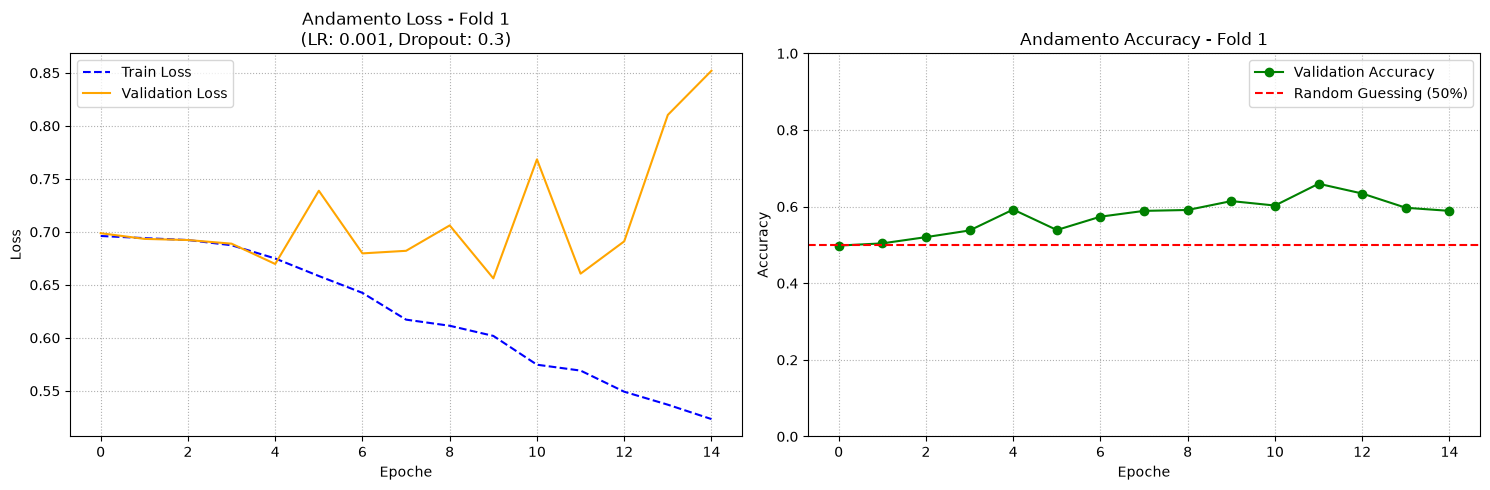


--- FOLD FINALE 2/5 (Cross-Subject) ---
Epoch 01/30: train_loss=0.69493, val_loss=0.69374, val_acc=49.83%
Epoch 02/30: train_loss=0.69238, val_loss=0.69325, val_acc=50.52%
Epoch 03/30: train_loss=0.69099, val_loss=0.69666, val_acc=50.29%
Epoch 04/30: train_loss=0.68187, val_loss=0.69641, val_acc=51.80%
Epoch 05/30: train_loss=0.65824, val_loss=0.70012, val_acc=58.30%
Epoch 06/30: train_loss=0.64985, val_loss=0.79217, val_acc=52.15%
Epoch 07/30: train_loss=0.62587, val_loss=0.80501, val_acc=53.66%
Early stopping all'epoca 7
✅ Fold 2 completato | Min Val Loss: 0.6933 | Max Val Acc: 58.30%


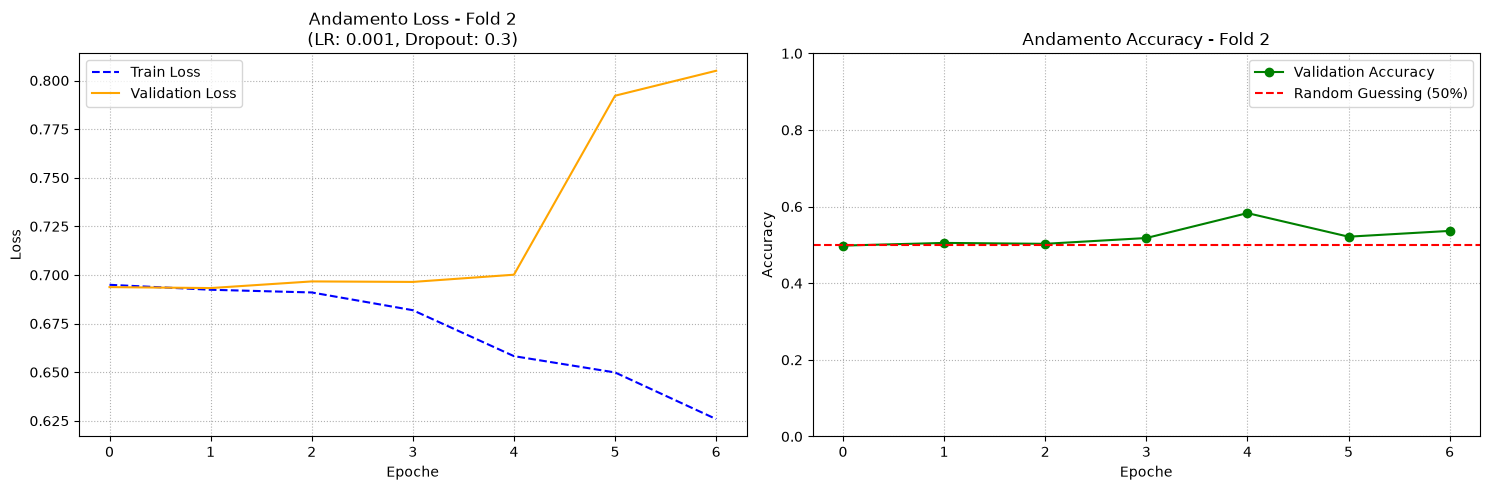


--- FOLD FINALE 3/5 (Cross-Subject) ---
Epoch 01/30: train_loss=0.69469, val_loss=0.69352, val_acc=49.44%
Epoch 02/30: train_loss=0.69285, val_loss=0.69277, val_acc=50.22%
Epoch 03/30: train_loss=0.69367, val_loss=0.68889, val_acc=54.48%
Epoch 04/30: train_loss=0.69095, val_loss=0.67448, val_acc=57.40%
Epoch 05/30: train_loss=0.68452, val_loss=0.64941, val_acc=62.67%
Epoch 06/30: train_loss=0.66179, val_loss=0.66573, val_acc=60.43%
Epoch 07/30: train_loss=0.63717, val_loss=0.62954, val_acc=67.60%
Epoch 08/30: train_loss=0.61950, val_loss=0.69780, val_acc=60.54%
Epoch 09/30: train_loss=0.60666, val_loss=0.60626, val_acc=68.72%
Epoch 10/30: train_loss=0.58424, val_loss=0.61288, val_acc=72.98%
Epoch 11/30: train_loss=0.56136, val_loss=0.80259, val_acc=58.63%
Epoch 12/30: train_loss=0.55745, val_loss=0.62355, val_acc=68.50%
Epoch 13/30: train_loss=0.52434, val_loss=0.62240, val_acc=71.97%
Epoch 14/30: train_loss=0.50191, val_loss=0.71331, val_acc=67.26%
Early stopping all'epoca 14
✅ Fold 

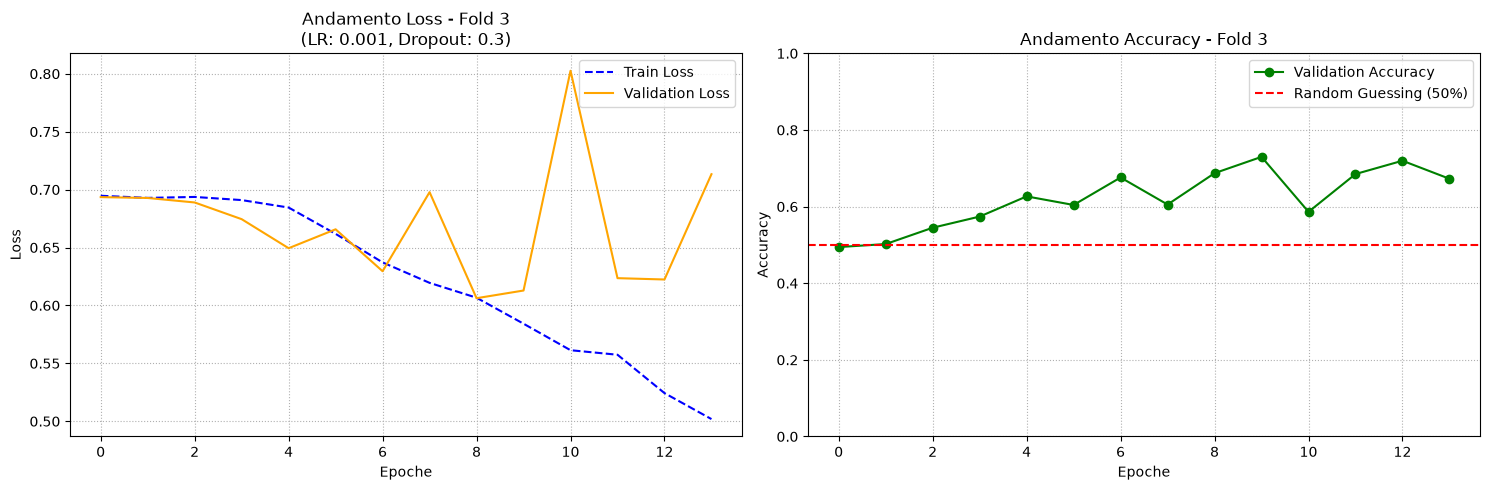


--- FOLD FINALE 4/5 (Cross-Subject) ---
Epoch 01/30: train_loss=0.69518, val_loss=0.69319, val_acc=49.44%
Epoch 02/30: train_loss=0.69288, val_loss=0.69087, val_acc=55.59%
Epoch 03/30: train_loss=0.69084, val_loss=0.68648, val_acc=54.59%
Epoch 04/30: train_loss=0.68546, val_loss=0.70252, val_acc=55.59%
Epoch 05/30: train_loss=0.66613, val_loss=0.72465, val_acc=59.28%
Epoch 06/30: train_loss=0.64942, val_loss=0.69176, val_acc=60.29%
Epoch 07/30: train_loss=0.61956, val_loss=0.67151, val_acc=65.77%
Epoch 08/30: train_loss=0.60895, val_loss=0.67316, val_acc=65.88%
Epoch 09/30: train_loss=0.59510, val_loss=0.67513, val_acc=65.88%
Epoch 10/30: train_loss=0.57946, val_loss=0.69742, val_acc=65.44%
Epoch 11/30: train_loss=0.55612, val_loss=0.70149, val_acc=68.79%
Epoch 12/30: train_loss=0.53522, val_loss=0.66642, val_acc=72.15%
Epoch 13/30: train_loss=0.51555, val_loss=0.66917, val_acc=68.90%
Epoch 14/30: train_loss=0.50818, val_loss=0.66701, val_acc=68.46%
Epoch 15/30: train_loss=0.49537, va

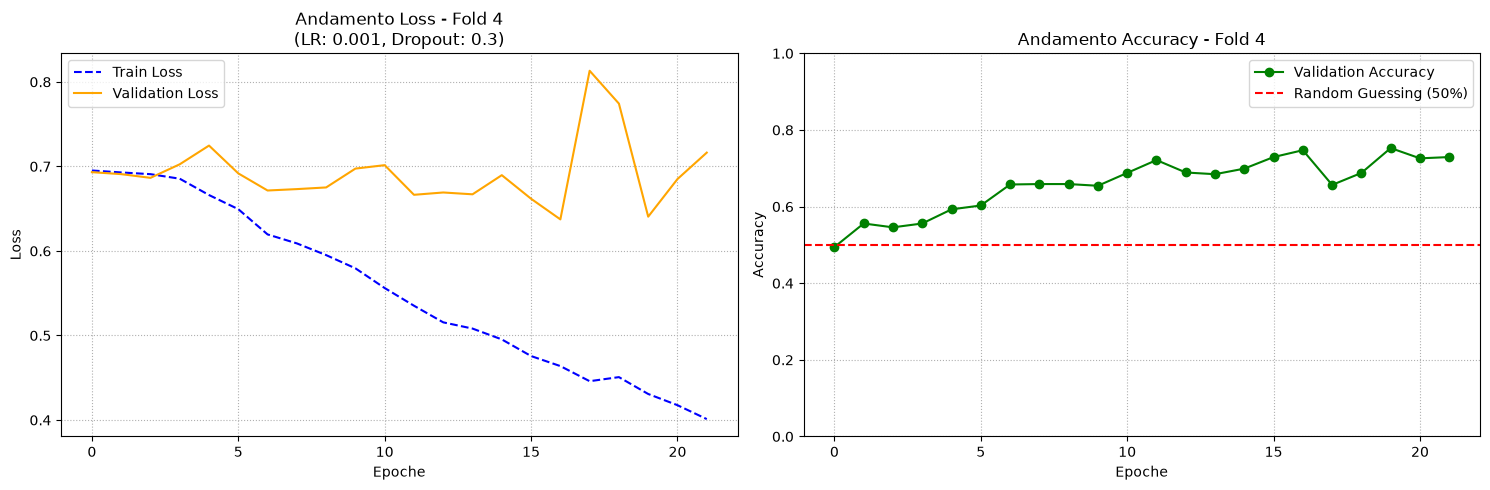


--- FOLD FINALE 5/5 (Cross-Subject) ---
Epoch 01/30: train_loss=0.69419, val_loss=0.69324, val_acc=50.00%
Epoch 02/30: train_loss=0.69345, val_loss=0.69086, val_acc=55.48%
Epoch 03/30: train_loss=0.68774, val_loss=0.68976, val_acc=51.68%
Epoch 04/30: train_loss=0.67697, val_loss=0.68306, val_acc=57.05%
Epoch 05/30: train_loss=0.67008, val_loss=0.69978, val_acc=52.68%
Epoch 06/30: train_loss=0.65049, val_loss=0.72882, val_acc=52.80%
Epoch 07/30: train_loss=0.64755, val_loss=0.65187, val_acc=59.84%
Epoch 08/30: train_loss=0.63047, val_loss=0.66395, val_acc=62.75%
Epoch 09/30: train_loss=0.61109, val_loss=0.65431, val_acc=65.21%
Epoch 10/30: train_loss=0.59615, val_loss=0.68302, val_acc=61.41%
Epoch 11/30: train_loss=0.57233, val_loss=0.62567, val_acc=67.00%
Epoch 12/30: train_loss=0.54788, val_loss=0.67372, val_acc=68.68%
Epoch 13/30: train_loss=0.52084, val_loss=0.74636, val_acc=60.74%
Epoch 14/30: train_loss=0.49715, val_loss=0.71114, val_acc=69.69%
Epoch 15/30: train_loss=0.48916, va

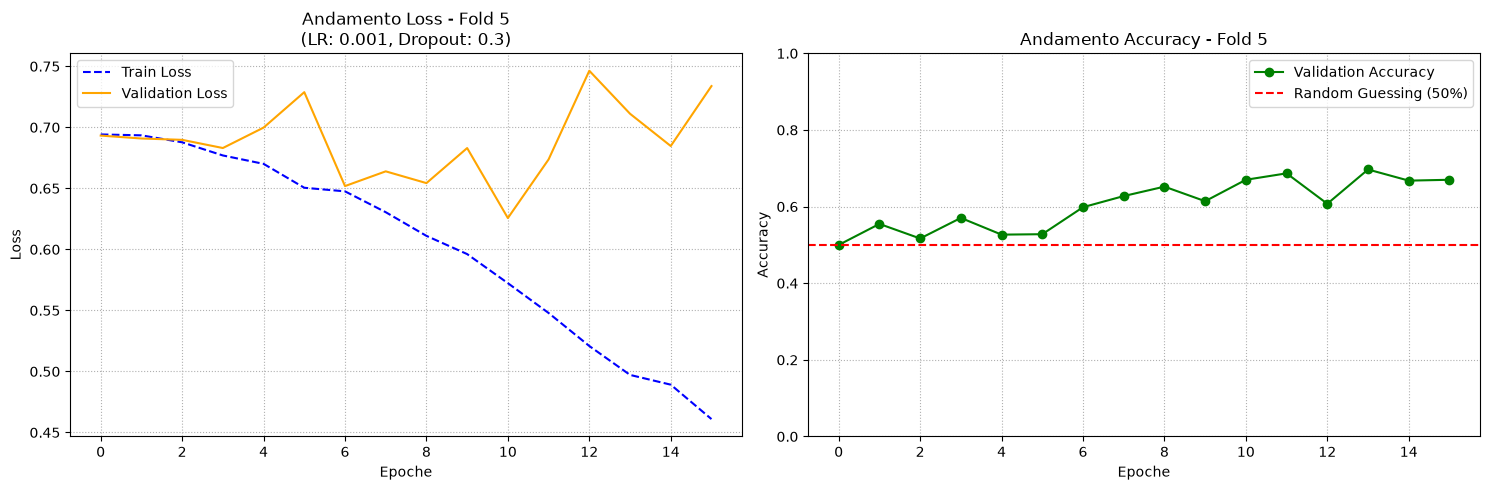


🎯 RISULTATO FINALE COMPLESSIVO (5 FOLD)
Accuracy media sui 5 fold: 68.44% (± 5.96%)
Validation Loss media (minima): 0.6437


In [10]:
# ==========================================
# 4. TRAINING FINALE E PLOT CON I MIGLIORI IPERPARAMETRI
# ==========================================
FINAL_EPOCHS = 30  # Usiamo tutte le epoche per il training definitivo
all_fold_best_accs = []
all_fold_best_losses = []

print(f"\n==========================================")
print(f"🚀 AVVIO TRAINING FINALE SUI 5 FOLD")
print(f"Usando i parametri vincenti: {best_hyperparams}")
print(f"==========================================")

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- FOLD FINALE {fold + 1}/5 (Cross-Subject) ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # Normalizzazione esclusiva sul train del fold (Prevenzione Data Leakage)
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    X_train_final = X_train_norm + (ALPHA_NOISE * np.random.randn(*X_train_norm.shape))
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_loader = DataLoader(EEGDataset(X_train_final, y_train), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(EEGDataset(X_val_final, y_val), batch_size=BATCH_SIZE, shuffle=False)

    # Inizializzazione del modello con i parametri ottimali della Grid Search
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, 
        dropout=best_hyperparams['dropout'], num_classes=2
    ).to(device)
    
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=best_hyperparams['lr'], weight_decay=best_hyperparams['weight_decay'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINAL_EPOCHS, eta_min=1e-6)

    trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)
    trainer.scheduler = scheduler

    # Esecuzione del training e della validazione
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, val_loader=val_loader, epochs=FINAL_EPOCHS
    )

    max_fold_acc = max(val_accuracies)
    min_fold_loss = min(val_losses)
    
    all_fold_best_accs.append(max_fold_acc)
    all_fold_best_losses.append(min_fold_loss)

    print(f"✅ Fold {fold + 1} completato | Min Val Loss: {min_fold_loss:.4f} | Max Val Acc: {max_fold_acc*100:.2f}%")

    # ==========================================
    # PLOT DELLE CURVE (Train Loss, Val Loss, Val Accuracy)
    # ==========================================
    plt.figure(figsize=(15, 5))

    # Grafico 1: Loss (Train vs Validation)
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento Loss - Fold {fold + 1}\n(LR: {best_hyperparams["lr"]}, Dropout: {best_hyperparams["dropout"]})')
    plt.xlabel('Epoche')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Grafico 2: Accuracy di Validazione
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

# ==========================================
# 5. REPORT STATISTICO FINALE COMPLESSIVO
# ==========================================
print(f"\n==========================================")
print(f"🎯 RISULTATO FINALE COMPLESSIVO (5 FOLD)")
print(f"==========================================")
print(f"Accuracy media sui 5 fold: {np.mean(all_fold_best_accs) * 100:.2f}% (± {np.std(all_fold_best_accs) * 100:.2f}%)")
print(f"Validation Loss media (minima): {np.mean(all_fold_best_losses):.4f}")

# KFold gridsearch

In [8]:
import itertools
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import KFold

# ==========================================
# 1. CONFIGURAZIONE DELLA GRID SEARCH CON K-FOLD
# ==========================================
param_grid = {
    'lr': [1e-3, 1e-4],
    'dropout': [0.3, 0.4, 0.5],
    'weight_decay': [1e-3, 1e-2]
}

keys = param_grid.keys()
combinations = [dict(zip(keys, prod)) for prod in itertools.product(*param_grid.values())]

# K-Fold classico richiesto
kf = KFold(n_splits=5, shuffle=True, random_state=42)

TUNING_EPOCHS = 20  # Epoche ridotte per velocizzare la valutazione sui fold
BATCH_SIZE = 64
ALPHA_NOISE = 0.01
epsilon = 1e-8

print(f"\n🧪 Spazio Grid Search: {len(combinations)} combinazioni da valutare con K-Fold (5 fold).")

best_overall_mean_acc = 0.0
best_hyperparams = None

# ==========================================
# 2. CICLO DI TUNING SUI 5 FOLD
# ==========================================
print("\n==========================================")
print("🔍 INIZIO GRID SEARCH CON K-FOLD CLASSICO")
print("==========================================")

for i, params in enumerate(combinations):
    print(f"\n--- Test Combinazione {i+1}/{len(combinations)} | LR: {params['lr']} | Dropout: {params['dropout']} | WD: {params['weight_decay']} ---")
    
    fold_max_accs = []
    
    # Eseguiamo i 5 fold per questa specifica combinazione
    for fold, (train_idx, val_idx) in enumerate(kf.split(X_training_validation_raw, y_training_validation)):
        
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        # Normalizzazione esclusiva sul training set del fold corrente (Prevenzione Data Leakage)
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

        X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
        X_train_final = X_train_norm + (ALPHA_NOISE * np.random.randn(*X_train_norm.shape))
        X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

        # DataLoader
        train_loader_t = DataLoader(EEGDataset(X_train_final, y_train), batch_size=BATCH_SIZE, shuffle=True)
        val_loader_t = DataLoader(EEGDataset(X_val_final, y_val), batch_size=BATCH_SIZE, shuffle=False)

        # Modello con i parametri correnti del test
        model_t = EEGConformer(
            num_channels=64, time_steps=641, d_model=32, 
            nhead=4, num_layers=1, d_ff=128, dropout=params['dropout'], num_classes=2
        ).to(device)
        
        criterion_t = nn.CrossEntropyLoss(label_smoothing=0.1)
        optimizer_t = optim.AdamW(model_t.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
        scheduler_t = optim.lr_scheduler.CosineAnnealingLR(optimizer_t, T_max=TUNING_EPOCHS, eta_min=1e-6)

        trainer_t = EEGTrainer(model=model_t, criterion=criterion_t, optimizer=optimizer_t, device=device)
        trainer_t.scheduler = scheduler_t

        # Training rapido sul fold
        _, _, _, val_accs_t = trainer_t.train_and_validate(
            train_loader=train_loader_t, val_loader=val_loader_t, epochs=TUNING_EPOCHS
        )

        fold_max_accs.append(max(val_accs_t))

    # Calcoliamo l'accuracy media sui 5 fold per questa combinazione
    mean_accuracy = np.mean(fold_max_accs)
    print(f"👉 Media Accuracy sui 5 fold: {mean_accuracy * 100:.2f}% (Singoli fold: {[f'{acc*100:.1f}%' for acc in fold_max_accs]})")

    # Aggiorniamo il record se questa combinazione batte la precedente
    if mean_accuracy > best_overall_mean_acc:
        best_overall_mean_acc = mean_accuracy
        best_hyperparams = params
        print(f"🎉 Nuovo record globale! Miglior Media: {best_overall_mean_acc * 100:.2f}%")

# ==========================================
# 3. RISULTATO FINALE DEL TUNING
# ==========================================
print(f"\n==========================================")
print(f"🏆 CONFIGURAZIONE VINCENTE DELLA GRID SEARCH:")
print(f"==========================================")
print(f"   - Iperparametri ottimali: {best_hyperparams}")
print(f"   - Media Accuracy di Cross-Validation: {best_overall_mean_acc * 100:.2f}%")
print(f"==========================================")


🧪 Spazio Grid Search: 12 combinazioni da valutare con K-Fold (5 fold).

🔍 INIZIO GRID SEARCH CON K-FOLD CLASSICO

--- Test Combinazione 1/12 | LR: 0.001 | Dropout: 0.3 | WD: 0.001 ---
Epoch 01/20: train_loss=0.69463, val_loss=0.69343, val_acc=48.81%
Epoch 02/20: train_loss=0.69284, val_loss=0.69248, val_acc=52.21%
Epoch 03/20: train_loss=0.69119, val_loss=0.69476, val_acc=50.28%
Epoch 04/20: train_loss=0.69231, val_loss=0.69243, val_acc=50.51%
Epoch 05/20: train_loss=0.68535, val_loss=0.70942, val_acc=51.08%
Epoch 06/20: train_loss=0.67356, val_loss=0.68630, val_acc=57.09%
Epoch 07/20: train_loss=0.66849, val_loss=0.66666, val_acc=56.64%
Epoch 08/20: train_loss=0.65204, val_loss=0.64592, val_acc=65.61%
Epoch 09/20: train_loss=0.65637, val_loss=0.64746, val_acc=62.20%
Epoch 10/20: train_loss=0.63625, val_loss=0.66628, val_acc=62.20%
Epoch 11/20: train_loss=0.61281, val_loss=0.74399, val_acc=56.87%
Epoch 12/20: train_loss=0.61013, val_loss=0.60042, val_acc=70.37%
Epoch 13/20: train_loss

In [1]:
#COSINE + gradient clipping

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURAZIONE FINALE CON I BEST PARAMETRI
# ==========================================
EPOCHS = 30  # Puoi usare il numero di epoche completo per il training finale
BATCH_SIZE = 64
ALPHA_NOISE = 0.01
epsilon = 1e-8

# Inserisci qui i migliori iperparametri trovati dalla Grid Search
# (Esempio basato sui valori tipici del tuo dizionario)
LR =0.0001       # es. 1e-3
DROPOUT = 0.5 # es. 0.4
WEIGHT_DECAY = 0.1 # es. 1e-2

# Scegli il numero di split (es. 3 o 5)
N_SPLITS = 5
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

all_fold_best_accs = []
all_fold_best_losses = []

print(f"\n==========================================")
print(f"🚀 TRAINING FINALE CON I MIGLIORI IPERPARAMETRI")
print(f"   - LR: {LR} | Dropout: {DROPOUT} | Weight Decay: {WEIGHT_DECAY}")
print(f"==========================================")

for fold, (train_idx, val_idx) in enumerate(kf.split(X_training_validation_raw, y_training_validation)):
    
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # Normalizzazione esclusiva sul train del fold (Prevenzione Data Leakage)
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    X_train_final = X_train_norm + (ALPHA_NOISE * np.random.randn(*X_train_norm.shape))
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # DataLoader
    train_loader = DataLoader(EEGDataset(X_train_final, y_train), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(EEGDataset(X_val_final, y_val), batch_size=BATCH_SIZE, shuffle=False)

    # Inizializzazione del modello con i best hyperparams
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, 
        dropout=DROPOUT, num_classes=2
    ).to(device)
    
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)
    trainer.scheduler = scheduler

    # Esecuzione del training e della validazione sul fold
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )
    

    max_fold_acc = max(val_accuracies)
    min_fold_loss = min(val_losses)
    
    all_fold_best_accs.append(max_fold_acc)
    all_fold_best_losses.append(min_fold_loss)

    print(f"✅ Fold {fold + 1} completato | Min Val Loss: {min_fold_loss:.4f} | Max Val Acc: {max_fold_acc*100:.2f}%")

    # ==========================================
    # PLOT DELLE CURVE PER QUESTO FOLD
    # ==========================================
    plt.figure(figsize=(15, 5))

    # Grafico 1: Train Loss vs Validation Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento Loss - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Grafico 2: Validation Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

    
# ==========================================
# REPORT STATISTICO FINALE
# ==========================================
print(f"\n==========================================")
print(f"🎯 RISULTATO FINALE COMPLESSIVO ({N_SPLITS}-FOLD)")
print(f"==========================================")
print(f"Accuracy media sui {N_SPLITS} fold: {np.mean(all_fold_best_accs) * 100:.2f}% (± {np.std(all_fold_best_accs) * 100:.2f}%)")
print(f"Validation Loss media (minima): {np.mean(all_fold_best_losses):.4f}")


🚀 TRAINING FINALE CON I MIGLIORI IPERPARAMETRI
   - LR: 0.0001 | Dropout: 0.5 | Weight Decay: 0.1


NameError: name 'X_training_validation_raw' is not defined

In [ ]:
# gradient clipping +

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURAZIONE FINALE CON I BEST PARAMETRI
# ==========================================
EPOCHS = 30  # Puoi usare il numero di epoche completo per il training finale
BATCH_SIZE = 64
ALPHA_NOISE = 0.01
epsilon = 1e-8

# Inserisci qui i migliori iperparametri trovati dalla Grid Search
# (Esempio basato sui valori tipici del tuo dizionario)
LR =0.0001       # es. 1e-3
DROPOUT = 0.5 # es. 0.4
WEIGHT_DECAY = 0.1 # es. 1e-2

# Scegli il numero di split (es. 3 o 5)
N_SPLITS = 5
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

all_fold_best_accs = []
all_fold_best_losses = []

print(f"\n==========================================")
print(f"🚀 TRAINING FINALE CON I MIGLIORI IPERPARAMETRI")
print(f"   - LR: {LR} | Dropout: {DROPOUT} | Weight Decay: {WEIGHT_DECAY}")
print(f"==========================================")

for fold, (train_idx, val_idx) in enumerate(kf.split(X_training_validation_raw, y_training_validation)):
    
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # Normalizzazione esclusiva sul train del fold (Prevenzione Data Leakage)
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    X_train_final = X_train_norm + (ALPHA_NOISE * np.random.randn(*X_train_norm.shape))
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # DataLoader
    train_loader = DataLoader(EEGDataset(X_train_final, y_train), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(EEGDataset(X_val_final, y_val), batch_size=BATCH_SIZE, shuffle=False)

    # Inizializzazione del modello con i best hyperparams
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, 
        dropout=DROPOUT, num_classes=2
    ).to(device)
    
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode='min',       # Monitora la discesa della validation loss
    factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
    patience=3,       # Se per 3 epoche la val loss non migliora, agisce
    
    )
    trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)
    trainer.scheduler = scheduler

    # Esecuzione del training e della validazione sul fold
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )
    

    max_fold_acc = max(val_accuracies)
    min_fold_loss = min(val_losses)
    
    all_fold_best_accs.append(max_fold_acc)
    all_fold_best_losses.append(min_fold_loss)

    print(f"✅ Fold {fold + 1} completato | Min Val Loss: {min_fold_loss:.4f} | Max Val Acc: {max_fold_acc*100:.2f}%")

    # ==========================================
    # PLOT DELLE CURVE PER QUESTO FOLD
    # ==========================================
    plt.figure(figsize=(15, 5))

    # Grafico 1: Train Loss vs Validation Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento Loss - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Grafico 2: Validation Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

    
# ==========================================
# REPORT STATISTICO FINALE
# ==========================================
print(f"\n==========================================")
print(f"🎯 RISULTATO FINALE COMPLESSIVO ({N_SPLITS}-FOLD)")
print(f"==========================================")
print(f"Accuracy media sui {N_SPLITS} fold: {np.mean(all_fold_best_accs) * 100:.2f}% (± {np.std(all_fold_best_accs) * 100:.2f}%)")
print(f"Validation Loss media (minima): {np.mean(all_fold_best_losses):.4f}")

# GroupKFold con gradiente clipping e scheduler

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69429, val_loss=0.69289, val_acc=51.45%
Epoch 02/30: train_loss=0.69340, val_loss=0.69225, val_acc=52.96%
Epoch 03/30: train_loss=0.69174, val_loss=0.69229, val_acc=54.82%
Epoch 04/30: train_loss=0.69050, val_loss=0.69239, val_acc=51.57%
Epoch 05/30: train_loss=0.68866, val_loss=0.69071, val_acc=52.96%
Epoch 06/30: train_loss=0.68665, val_loss=0.69010, val_acc=53.08%
Epoch 07/30: train_loss=0.68536, val_loss=0.68904, val_acc=56.79%
Epoch 08/30: train_loss=0.68314, val_loss=0.68673, val_acc=55.05%
Epoch 09/30: train_loss=0.68066, val_loss=0.68487, val_acc=54.24%
Epoch 10/30: train_loss=0.67654, val_loss=0.68379, val_acc=56.91%
Epoch 11/30: train_loss=0.67666, val_loss=0.68102, val_acc=57.84%
Epoch 12/30: train_loss=0.66825, val_loss=0.67436, val_acc=56.45%
Epoch 13/30: train_loss=0.66125, val_loss=0.68057, val_acc=58.77%
Epoch 14/30: train_loss=0.65173,

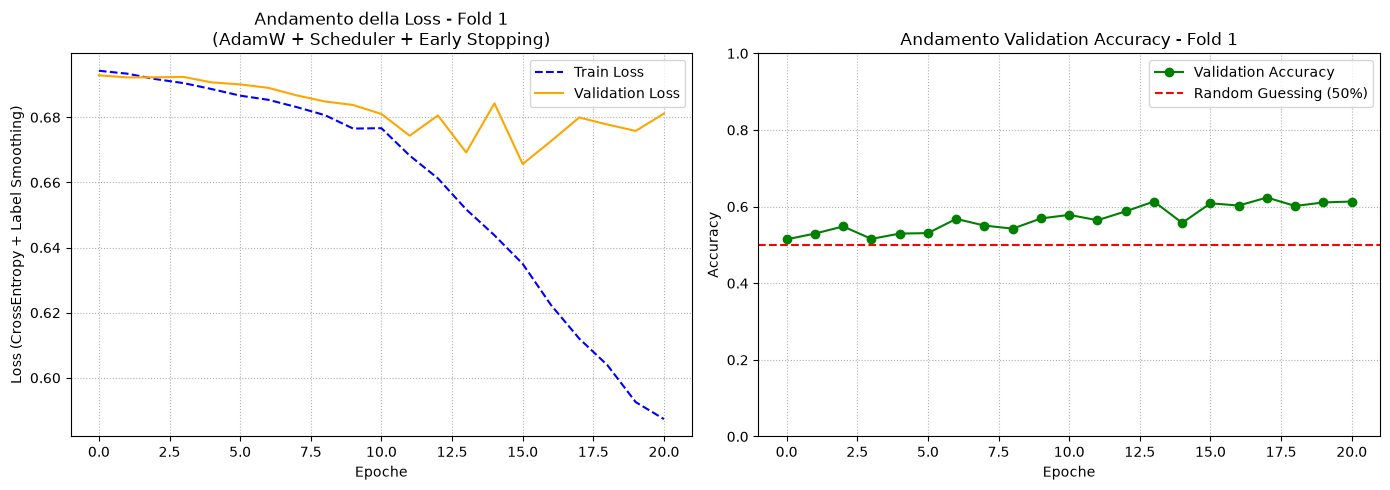


--- INIZIO TRAINING & VALIDAZIONE - FOLD 2/5 (Batch Size = 64) ---
Epoch 01/30: train_loss=0.69940, val_loss=0.69397, val_acc=49.83%
Epoch 02/30: train_loss=0.69453, val_loss=0.69245, val_acc=53.54%
Epoch 03/30: train_loss=0.69200, val_loss=0.69236, val_acc=51.45%
Epoch 04/30: train_loss=0.69088, val_loss=0.69156, val_acc=53.77%
Epoch 05/30: train_loss=0.69091, val_loss=0.69109, val_acc=54.24%
Epoch 06/30: train_loss=0.68750, val_loss=0.69065, val_acc=52.15%


KeyboardInterrupt: 

In [ ]:
import itertools
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# ==========================================
# 1. CONFIGURAZIONE DEL DISPOSITIVO
# ==========================================
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# ==========================================
# 2. PARAMETRI GENERALI E GRID SEARCH
# ==========================================
BATCH_SIZE = 64
ALPHA_NOISE = 0.01

# Definizione dello spazio degli iperparametri da testare
param_grid = {
    'lr': [1e-3, 1e-4],
    'dropout': [0.3, 0.5],
    'weight_decay': [1e-3, 1e-2]
}

keys = param_grid.keys()
combinations = [dict(zip(keys, prod)) for prod in itertools.product(*param_grid.values())]

gkf = GroupKFold(n_splits=5)

print(f"\n🧪 Spazio Grid Search definito: {len(combinations)} combinazioni da testare.")

# Estraiamo il primo fold di gruppo come riferimento per il tuning degli iperparametri
for train_idx, val_idx in gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation):
    X_train_t_raw = X_training_validation_raw[train_idx]
    y_train_t = y_training_validation[train_idx]
    X_val_t_raw = X_training_validation_raw[val_idx]
    y_val_t = y_training_validation[val_idx]
    break  # Ci basta il primo split per trovare i parametri

# Normalizzazione preliminare per il tuning
t_mean = np.mean(X_train_t_raw, axis=(0, 2), keepdims=True)  
t_std = np.std(X_train_t_raw, axis=(0, 2), keepdims=True)
epsilon = 1e-8

X_train_t_norm = (X_train_t_raw - t_mean) / (t_std + epsilon)
X_train_t_final = X_train_t_norm + (ALPHA_NOISE * np.random.randn(*X_train_t_norm.shape))
X_val_t_final = (X_val_t_raw - t_mean) / (t_std + epsilon)

train_loader_grid = DataLoader(EEGDataset(X_train_t_final, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader_grid = DataLoader(EEGDataset(X_val_t_final, y_val_t), batch_size=BATCH_SIZE, shuffle=False)

best_overall_acc = 0.0
best_hyperparams = None
TUNING_EPOCHS = 30  

print("\n==========================================")
print("🔍 INIZIO GRID SEARCH (CROSS-SUBJECT)")
print("==========================================")

for i, params in enumerate(combinations):
    print(f"Test {i+1}/{len(combinations)} | LR: {params['lr']} | Dropout: {params['dropout']} | WD: {params['weight_decay']}")
    
    model_t = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, dropout=params['dropout'], num_classes=2
    ).to(device)
    
    criterion_t = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer_t = optim.AdamW(model_t.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode='min',       # Monitora la discesa della validation loss
    factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
    patience=3,       # Se per 3 epoche la val loss non migliora, agisce
    verbose=True
    )

    trainer_t = EEGTrainer(model=model_t, criterion=criterion_t, optimizer=optimizer_t, device=device)
    trainer_t.scheduler = scheduler_t

    _, _, _, val_accs_t = trainer_t.train_and_validate(
        train_loader=train_loader_grid, val_loader=val_loader_grid, epochs=TUNING_EPOCHS
    )

    current_max_acc = max(val_accs_t)
    if current_max_acc > best_overall_acc:
        best_overall_acc = current_max_acc
        best_hyperparams = params
        print(f"🎉 Nuovo record provvisorio! Max Accuracy: {best_overall_acc * 100:.2f}%")

print(f"\n🏆 CONFIGURAZIONE VINCENTE TROVATA DALLA GRID SEARCH:")
print(f"   - Parametri: {best_hyperparams}")
print(f"   - Max Accuracy di Tuning: {best_overall_acc * 100:.2f}%\n")

